# Ось N — шум: яркий посторонний факт рядом с иглой

Подробный разбор одной оси по прогонам `results/new/qwen3_hard_fast/N`. Общая картина по всем осям — в `hard_context.ipynb`, описание данных — в `data/needles_hard/README.md`.

Ноутбук читает только готовые результаты, модель не нужна.

| Раздел | Что показывает |
|---|---|
| 1 | о чём ось: иглы, вопросы и шумовые вставки всех трёх семейств |
| 2 | качество без маски; проникает ли шум в ответы |
| 3 | маскирование: доля верных при 40 и 60 лучших и 60 случайных головах, по уровням, рядом с A0 |
| 4 | перефразы: как модель переписывает факты при маске и насколько класс «верно» их недосчитывает |
| 5 | куда смотрят головы: на иглу или на шум; какие головы смотрят на шум |
| 6 | остаются ли лучшие головы лучшими на уровнях с шумом |
| 7 | выводы и особенности |

## 0. Настройки

In [41]:
import json, os, re, sys, unicodedata
sys.path.insert(0, os.path.abspath(".."))   # корень репозитория: ноутбук лежит в vizual/

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from vizual import data, plots, style

RUNS_DIR = "results/new/qwen3_hard_fast"     # <ось>/<прогон>
AXIS = "N"
RUNS = ["none", "top40", "top60", "random60"]
RANKING = "results/new/qwen3_detect/head_score_copy_count.json"   # по нему выбирались маскируемые головы
NEEDLES = "data/needles_hard"
FAMILIES = ["lisbon", "cairo", "oslo"]

LAYERS, N_HEADS = list(range(36)), 32
TOP = 20                  # сколько лучших голов детекции смотреть в разделах 5 и 6
BOOT = 2000               # повторов бутстрепа
SEED = 0
SAVE = False              # сохранять рисунки в vizual/figures/

style.use(scale=1.0, dpi=110)
T = style.THEME

def show(ax, name):
    if SAVE:
        plots.save(np.ravel(ax)[0].figure, name)
    plt.show()


CLASSES = ["correct", "mixed", "partial", "confusion", "noise", "other"]
CLASS_LABELS = {"correct": "верно", "mixed": "смешано", "partial": "частично", "confusion": "путаница", "noise": "шум", "other": "иное"}
CLASS_COLORS = {"correct": T.colors["top"], "mixed": "#9cc3ee", "partial": "#f2c46b", "confusion": T.colors["random"],
                "noise": "#7a4fd6", "other": T.colors["muted"]}
RUN_LABELS = {"none": "без маски", "top40": "40 лучших", "top60": "60 лучших", "random60": "60 случайных"}
RUN_COLORS = {"none": T.colors["none"], "top40": "#86b4ea", "top60": T.colors["top"], "random60": T.colors["random"]}
plots.VALUE_LABELS["correct"] = "верных ответов, %"


def plain(text):
    return re.sub(r"\s+", " ", re.sub(r"[^\w\s]", " ", unicodedata.normalize("NFKC", text).lower())).strip()


def has_fact(text, fact):
    """Одно из написаний факта стоит в тексте целыми словами (как has_fact в rh/metrics.py)."""
    text = f" {plain(text)} "
    return any(f" {plain(spelling)} " in text for spelling in fact)


def facts(value):
    """Список фактов из строки samples.jsonl; у примеров без вставок поля может не быть (NaN)."""
    return value if isinstance(value, list) else []


def fact_class(row):
    """Класс ответа по фактам — то же правило, что fact_class в rh/metrics.py (README, раздел 5)."""
    found = sum(has_fact(row["response"], f) for f in row["answer_key"])
    confused = any(has_fact(row["response"], f) for f in facts(row.get("confusion_facts")))
    noisy = any(has_fact(row["response"], f) for f in facts(row.get("noise_facts")))
    if found == len(row["answer_key"]):
        name = "mixed" if confused or noisy else "correct"
    else:
        name = "confusion" if confused else "noise" if noisy else "partial" if found else "other"
    return pd.Series({"answer_class": name, "facts_found": found / len(row["answer_key"])})


def bootstrap(values, n=BOOT, seed=SEED):
    """Среднее и 95% интервал бутстрепа по примерам, в процентах."""
    v = np.asarray(values, dtype=float)
    if len(v) == 0:
        return np.nan, np.nan, np.nan
    boots = np.random.default_rng(seed).choice(v, (n, len(v))).mean(1)
    return 100 * v.mean(), 100 * np.percentile(boots, 2.5), 100 * np.percentile(boots, 97.5)


def stacked(df, column, order, labels, colors, by, by_order, by_labels=None, ax=None, legend=True, title=None, subtitle=None, annotate=None):
    """Доли значений столбца column столбиками по значениям by; annotate — значение, долю которого подписать внутри столбика."""
    ax = plots.new_ax(ax, 0.9 * len(by_order) + 3.2, 4.2)
    share = (df.groupby(by)[column].value_counts(normalize=True).unstack(fill_value=0) * 100).reindex(index=by_order, columns=order, fill_value=0)
    xs, bottom = np.arange(len(by_order)), np.zeros(len(by_order))
    for value in order:
        ax.bar(xs, share[value], bottom=bottom, width=0.66, color=colors[value], edgecolor=T.surface, linewidth=1.2, label=labels[value])
        bottom += share[value].to_numpy()
    if annotate is not None:
        for x, v in zip(xs, share[annotate]):
            if v >= 8:
                ax.annotate(f"{v:.0f}", (x, v / 2), ha="center", va="center", color=T.surface, fontsize=T.font - 1, fontweight="semibold")
    ax.set_xticks(xs, by_labels or by_order)
    ax.tick_params(axis="x", length=0)
    ax.grid(axis="y", visible=False)
    ax.set_ylim(0, 100)
    plots.round_axis(ax, "y", 0, 100, 20)
    ax.set_ylabel("доля ответов, %")
    if legend:
        ax.legend(loc="center left", bbox_to_anchor=(1.01, 0.5), reverse=True)
    plots.titles(ax, title, subtitle)
    return ax


def class_bars(df, by, by_order, **kwargs):
    return stacked(df, "answer_class", CLASSES, CLASS_LABELS, CLASS_COLORS, by, by_order, annotate="correct", **kwargs)

## 1. О чём ось N

Игла и вопрос — те же, что на A0. Рядом с иглой ставится **яркий факт, не связанный с вопросом**: экстренная новость о катастрофе. Он не похож на иглу по структуре и не делит с вопросом ни одного слова (кроме N4, где совпадает город). Ось проверяет, перетягивает ли на себя внимание сама «громкость» текста.

| Уровень | Что вставлено | Где | Что меняется по сравнению с предыдущим |
|---|---|---|---|
| N1 | метеорит упал в Тихий океан | далеко: на противоположной глубине | — |
| N2 | тот же метеорит | рядом, в пределах 200 токенов | расстояние |
| N3 | метеорит + вулкан Korvath + Луна улетает от Земли | рядом | количество шумовых фактов: 1 → 3 |
| N4 | метеорит упал **под тем же городом**, что в игле | рядом | шум делит с вопросом ключ (название города) |

Ответ с фактами шума (meteorite, tsunami, volcano, Korvath, drift away, glare) и без всех фактов иглы попадает в класс **«шум»**.

Ниже — иглы, вопросы и тексты вставок прямо из файлов данных.

In [42]:
pd.set_option("display.max_colwidth", 400)
needles, inserts = {}, {}
for family in FAMILIES:
    with open(data.path(f"{NEEDLES}/{family}/axis_{AXIS}.jsonl"), encoding="utf-8") as f:
        needles[family] = json.loads(f.readline())
    with open(data.path(f"{NEEDLES}/{family}/inserts_{AXIS}.json"), encoding="utf-8") as f:
        inserts[family] = json.load(f)

display(pd.DataFrame([{"семейство": fam, "игла": r["needle"], "вопрос": r["question"], "факты ответа": "; ".join(k[0] for k in r["answer_key"])}
                      for fam, r in needles.items()]).set_index("семейство"))

rows = []
for family, ins in inserts.items():
    for level, s in ins["levels"].items():
        rows.append({"уровень": level, "семейство": family, "где": s["placement"],
                     "вставки": " | ".join(ins["inserts"][name]["text"] for name in s["use"])})
levels_table = pd.DataFrame(rows)
# у N1–N3 тексты одинаковы во всех семействах, у N4 различается только город
levels_table.drop_duplicates(subset=["уровень", "вставки"]).set_index(["уровень", "семейство"])

,игла,вопрос,факты ответа
семейство,,,
lisbon,Every visitor to the Lisbon Tram Museum is asked to ring the brass bell at the entrance and sign the guest book with a green pen.,What is every visitor to the Lisbon Tram Museum asked to do?,brass bell; guest book
cairo,The famous soup of the Zahira Cafe in Cairo is cooked with smoked lemon peel and served in a bowl of black clay.,How is the famous soup of the Zahira Cafe in Cairo cooked and served?,lemon peel; black clay
oslo,The oldest house in Oslo has a roof of red slate and a door painted with a white reindeer.,What does the oldest house in Oslo have?,red slate; white reindeer


где  \
уровень семейство         
N1      lisbon      far   
N2      lisbon     near   
N3      lisbon     near   
N4      lisbon     near   
        cairo      near   
        oslo       near   

                                                                                                                                                                                                                                                                                                                                                                                                                           вставки  
уровень семейство                                                                                                                                                                                                                                                                                                                                                                                                                   
N1      lisbon                                                                                                                                                                                                                                                                   BREAKING NEWS: a giant meteorite has just crashed into the Pacific Ocean, and scientists warn that a huge tsunami may hit the coast within hours.  
N2      lisbon                                                                                                                                                                                                                                                                   BREAKING NEWS: a giant meteorite has just crashed into the Pacific Ocean, and scientists warn that a huge tsunami may hit the coast within hours.  
N3      lisbon     BREAKING NEWS: a giant meteorite has just crashed into the Pacific Ocean, and scientists warn that a huge tsunami may hit the coast within hours. | URGENT: the Korvath volcano in Iceland has exploded with a force of ten nuclear bombs, and ash has already covered half of Europe. | Astronomers have confirmed a shocking discovery: the Moon has started to drift away from the Earth a thousand times...  
N4      lisbon                                                                                                                                                                                                                                                                            BREAKING NEWS: a burning meteorite has fallen on the outskirts of Lisbon, and thousands of people saw a blinding glare in the night sky.  
        cairo                                                                                                                                                                                                                                                                              BREAKING NEWS: a burning meteorite has fallen on the outskirts of Cairo, and thousands of people saw a blinding glare in the night sky.  
        oslo                                                                                                                                                                                                                                                                                BREAKING NEWS: a burning meteorite has fallen on the outskirts of Oslo, and thousands of people saw a blinding glare in the night sky.

### Загрузка

Таблица `both`: ось N и уровень A0 оси A (точка отсчёта — та же игла без вставок). У A0 те же прогоны и те же головы в маске.

In [43]:
def load(axis):
    parts = []
    for run in RUNS:
        out = f"{RUNS_DIR}/{axis}/{run}"
        if not os.path.exists(os.path.join(data.path(out), "samples.jsonl")):
            print("нет прогона:", out)
            continue
        parts.append(data.load_run(out, name=run).assign(axis=axis))
    df = pd.concat(parts, ignore_index=True)
    df[["answer_class", "facts_found"]] = df.apply(fact_class, axis=1)
    df["correct"] = df["answer_class"] == "correct"
    return df

noise_axis = load(AXIS)
a_axis = load("A")
both = pd.concat([a_axis[a_axis["level"] == "A0"], noise_axis], ignore_index=True)
LEVELS = ["A0"] + sorted(noise_axis["level"].unique())
none = both[both["run"] == "none"]

print(f"примеров: ось N — {len(noise_axis)}, A0 — {len(both) - len(noise_axis)}")
both.groupby(["level", "run"]).size().unstack()[RUNS].reindex(LEVELS)

примеров: ось N — 3168, A0 — 792


run,none,top40,top60,random60
level,,,,
A0,198,198,198,198
N1,198,198,198,198
N2,198,198,198,198
N3,198,198,198,198
N4,198,198,198,198


## 2. Качество без маски

Таблица: доли классов, ROUGE-1 > 50 и точная фраза по уровням, затем то же по семействам.

In [44]:
def class_table(df, by):
    share = df.groupby(by)["answer_class"].value_counts(normalize=True).unstack(fill_value=0).reindex(columns=CLASSES, fill_value=0) * 100
    extra = df.groupby(by).agg(примеров=("id", "size"), ROUGE1_больше_50=("success", "mean"), точная_фраза=("exact", "mean"))
    extra[["ROUGE1_больше_50", "точная_фраза"]] *= 100
    return extra.join(share.rename(columns=CLASS_LABELS)).round(1)

display(class_table(none, "level").reindex(LEVELS))
none.pivot_table(index="family", columns="level", values="correct", aggfunc="mean").reindex(columns=LEVELS).mul(100).round(1)

,примеров,ROUGE1_больше_50,точная_фраза,верно,смешано,частично,путаница,шум,иное
level,,,,,,,,,
A0,198,100.0,100.0,100.0,0,0,0,0,0
N1,198,100.0,100.0,100.0,0,0,0,0,0
N2,198,100.0,100.0,100.0,0,0,0,0,0
N3,198,100.0,100.0,100.0,0,0,0,0,0
N4,198,100.0,100.0,100.0,0,0,0,0,0


level,A0,N1,N2,N3,N4
family,,,,,
cairo,100.0,100.0,100.0,100.0,100.0
lisbon,100.0,100.0,100.0,100.0,100.0
oslo,100.0,100.0,100.0,100.0,100.0


### 2.1. Проникает ли шум в ответ

Класс «шум» считается только по фактам из `noise_facts`. Здесь шире: доля ответов, в которых встречается **любое** слово шумовых вставок (метеорит, цунами, вулкан, Луна, вспышка, «breaking news», «urgent»), — во всех прогонах, включая маску. Если шум перетягивает внимание, это первое место, где он проявится.

In [45]:
NOISE_WORDS = ["meteorite", "meteor", "tsunami", "volcano", "korvath", "moon", "drift away", "glare", "breaking news", "urgent",
               "iceland", "pacific", "nuclear", "astronomers"]

def mentions(text, words=NOISE_WORDS):
    t = f" {plain(text)} "
    return [w for w in words if f" {w} " in t]

both["noise_words"] = both["response"].map(mentions)
both["noise_leak"] = both["noise_words"].str.len() > 0
leak = both.pivot_table(index="level", columns="run", values="noise_leak", aggfunc="mean").reindex(index=LEVELS, columns=RUNS) * 100
print(f"ответов со словами шума: {int(both['noise_leak'].sum())} из {len(both)}")
display(leak.round(1).rename(columns=RUN_LABELS))
both.loc[both["noise_leak"], ["level", "run", "family", "noise_words", "response"]].head(20)

ответов со словами шума: 0 из 3960


run,без маски,40 лучших,60 лучших,60 случайных
level,,,,
A0,0.0,0.0,0.0,0.0
N1,0.0,0.0,0.0,0.0
N2,0.0,0.0,0.0,0.0
N3,0.0,0.0,0.0,0.0
N4,0.0,0.0,0.0,0.0


,level,run,family,noise_words,response


### 2.2. Карты «длина × глубина» без маски

Доля верных ответов; в клетке 3 примера (по одному на семейство).

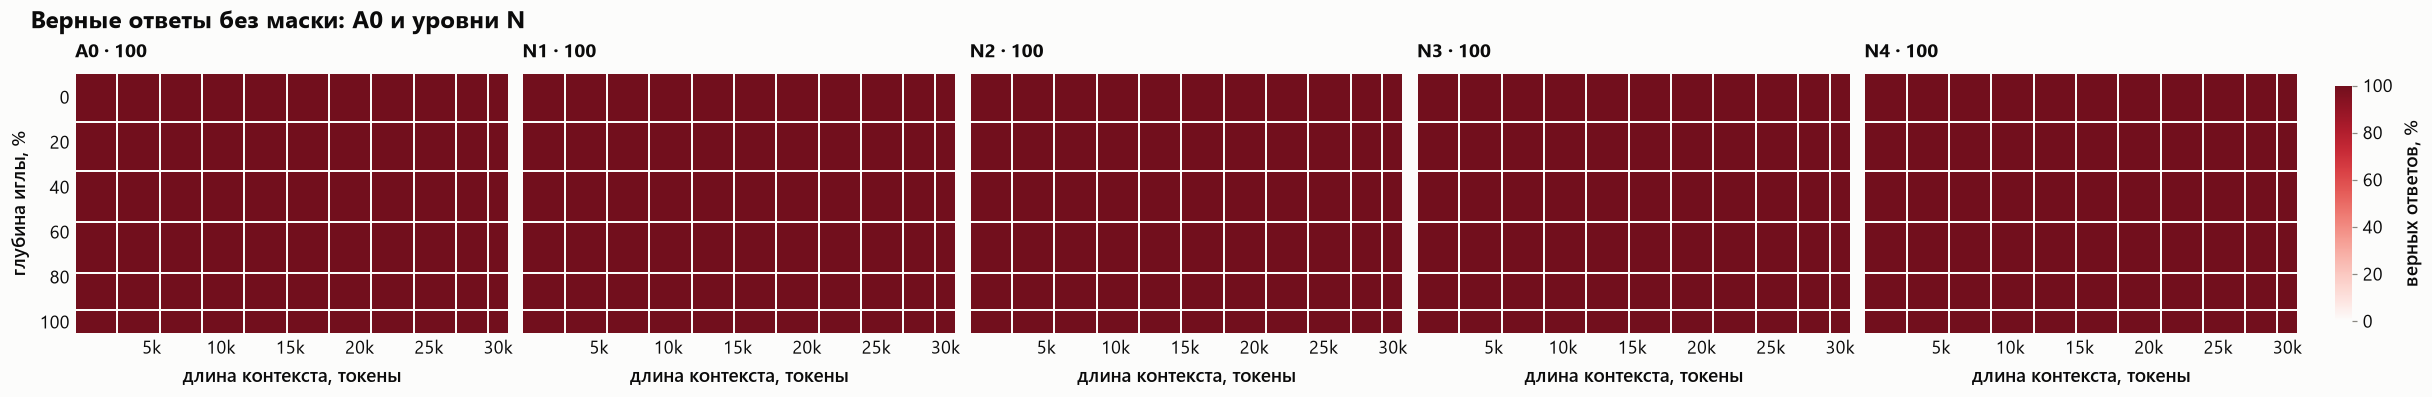

In [46]:
show(plots.niah_grid(none.assign(run=none["level"]), {lv: lv for lv in LEVELS}, value="correct", columns=5,
                     title="Верные ответы без маски: A0 и уровни N"), "axisN_niah_none")

## 3. Маскирование

Те же промпты с отключёнными головами: 40 и 60 лучших по `copy_count` простой задачи и 60 случайных вне 100 лучших. A0 стоит первым: если уровень N при маске ведёт себя как A0, шум ничего не добавляет к зависимости от голов.

### 3.1. Доля верных по уровням

Точка — доля верных, отрезок — 95% интервал бутстрепа по 198 примерам уровня.

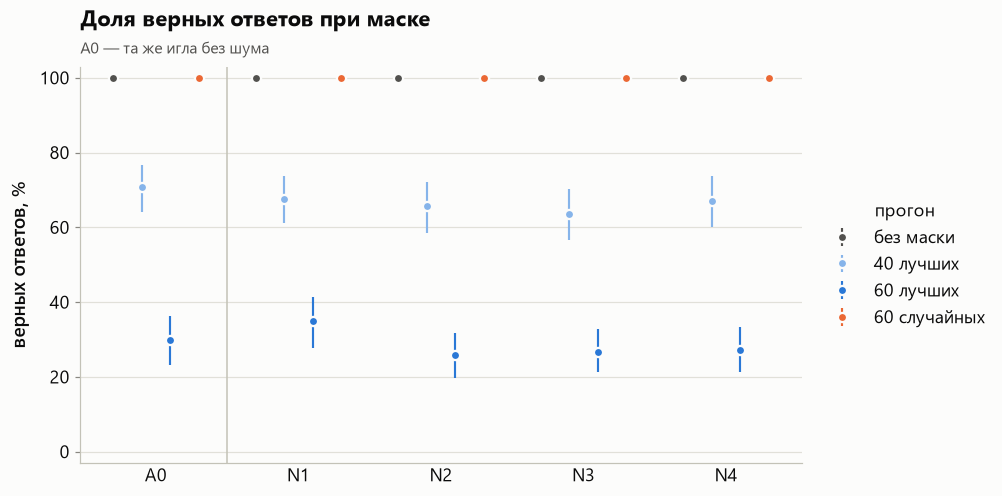

run,без маски,40 лучших,60 лучших,60 случайных
level,,,,
A0,100.0,70.7,29.8,100.0
N1,100.0,67.7,34.8,100.0
N2,100.0,65.7,25.8,100.0
N3,100.0,63.6,26.8,100.0
N4,100.0,67.2,27.3,100.0


In [47]:
rows = []
for (level, run), part in both.groupby(["level", "run"]):
    mean, lo, hi = bootstrap(part["correct"])
    rows.append({"level": level, "run": run, "correct": mean, "lo": lo, "hi": hi})
by_run = pd.DataFrame(rows)

ax = plt.subplots(figsize=style.size(9, 4.4))[1]
width = 0.8 / len(RUNS)
for i, run in enumerate(RUNS):
    part = by_run[by_run["run"] == run].set_index("level").reindex(LEVELS)
    xs = np.arange(len(LEVELS)) + (i - (len(RUNS) - 1) / 2) * width
    ax.errorbar(xs, part["correct"], yerr=[part["correct"] - part["lo"], part["hi"] - part["correct"]], fmt="o",
                color=RUN_COLORS[run], ecolor=RUN_COLORS[run], elinewidth=1.4, capsize=0, label=RUN_LABELS[run])
ax.axvline(0.5, color=T.axis, linewidth=1)
ax.set_xticks(range(len(LEVELS)), LEVELS)
ax.tick_params(axis="x", length=0)
ax.set_ylim(-3, 103)
plots.round_axis(ax, "y", 0, 100, 20)
ax.set_ylabel("верных ответов, %")
ax.legend(loc="center left", bbox_to_anchor=(1.01, 0.5), title="прогон")
plots.titles(ax, "Доля верных ответов при маске", "A0 — та же игла без шума")
show(ax, "axisN_mask_correct")

by_run.pivot_table(index="level", columns="run", values="correct").reindex(index=LEVELS, columns=RUNS).round(1).rename(columns=RUN_LABELS)

### 3.2. Эффект маски по сравнению с A0

`Δ_net = p_верно(60 случайных) − p_верно(60 лучших)` и полное падение `p_верно(без маски) − p_верно(60 лучших)`, парный бутстреп по примерам. Если столбики N совпадают с A0 в пределах интервалов, шум не меняет того, насколько ответ держится на лучших головах.

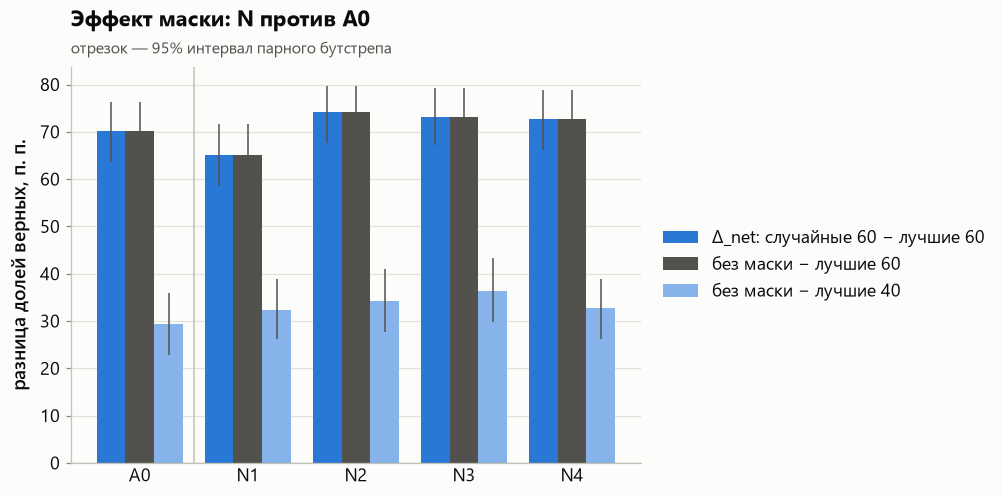

сравнение,Δ_net: случайные 60 − лучшие 60,без маски − лучшие 60,без маски − лучшие 40
level,,,
A0,70.2 [63.6; 76.3],70.2 [63.6; 76.3],29.3 [22.7; 35.9]
N1,65.2 [58.6; 71.7],65.2 [58.6; 71.7],32.3 [26.2; 38.9]
N2,74.2 [67.7; 79.8],74.2 [67.7; 79.8],34.3 [27.8; 40.9]
N3,73.2 [67.2; 79.3],73.2 [67.2; 79.3],36.4 [29.8; 43.4]
N4,72.7 [66.2; 78.8],72.7 [66.2; 78.8],32.8 [26.3; 38.9]


In [48]:
def paired_delta(part, a, b):
    """p(a) − p(b) по одним и тем же примерам, в процентах, с 95% интервалом бутстрепа."""
    wide = part.assign(c=part["correct"].astype(float)).pivot_table(index="id", columns="run", values="c", aggfunc="first").dropna(subset=[a, b])
    return bootstrap(wide[a] - wide[b])

COMPARE = {"Δ_net: случайные 60 − лучшие 60": ("random60", "top60"), "без маски − лучшие 60": ("none", "top60"),
           "без маски − лучшие 40": ("none", "top40")}
rows = []
for level, part in both.groupby("level"):
    for name, (a, b) in COMPARE.items():
        mean, lo, hi = paired_delta(part, a, b)
        rows.append({"level": level, "сравнение": name, "delta": mean, "lo": lo, "hi": hi})
deltas = pd.DataFrame(rows)

ax = plt.subplots(figsize=style.size(9, 4.4))[1]
width = 0.8 / len(COMPARE)
for i, (name, color) in enumerate(zip(COMPARE, (T.colors["top"], T.colors["none"], "#86b4ea"))):
    part = deltas[deltas["сравнение"] == name].set_index("level").reindex(LEVELS)
    xs = np.arange(len(LEVELS)) + (i - (len(COMPARE) - 1) / 2) * width
    ax.bar(xs, part["delta"], width=width, color=color, label=name)
    ax.errorbar(xs, part["delta"], yerr=[part["delta"] - part["lo"], part["hi"] - part["delta"]], fmt="none", ecolor=T.ink_secondary, elinewidth=1)
ax.axvline(0.5, color=T.axis, linewidth=1)
ax.axhline(0, color=T.ink_muted, linewidth=0.8)
ax.set_xticks(range(len(LEVELS)), LEVELS)
ax.tick_params(axis="x", length=0)
ax.set_ylabel("разница долей верных, п. п.")
ax.legend(loc="center left", bbox_to_anchor=(1.01, 0.5))
plots.titles(ax, "Эффект маски: N против A0", "отрезок — 95% интервал парного бутстрепа")
show(ax, "axisN_mask_delta")

deltas.assign(текст=lambda d: d.apply(lambda r: f"{r['delta']:.1f} [{r['lo']:.1f}; {r['hi']:.1f}]", axis=1)).pivot_table(
    index="level", columns="сравнение", values="текст", aggfunc="first").reindex(index=LEVELS)[list(COMPARE)]

### 3.3. Во что превращаются ответы

Классы ответов в четырёх прогонах, по панели на уровень. Если бы шум перетягивал модель при ослабленном поиске, при маске вырос бы класс «шум».

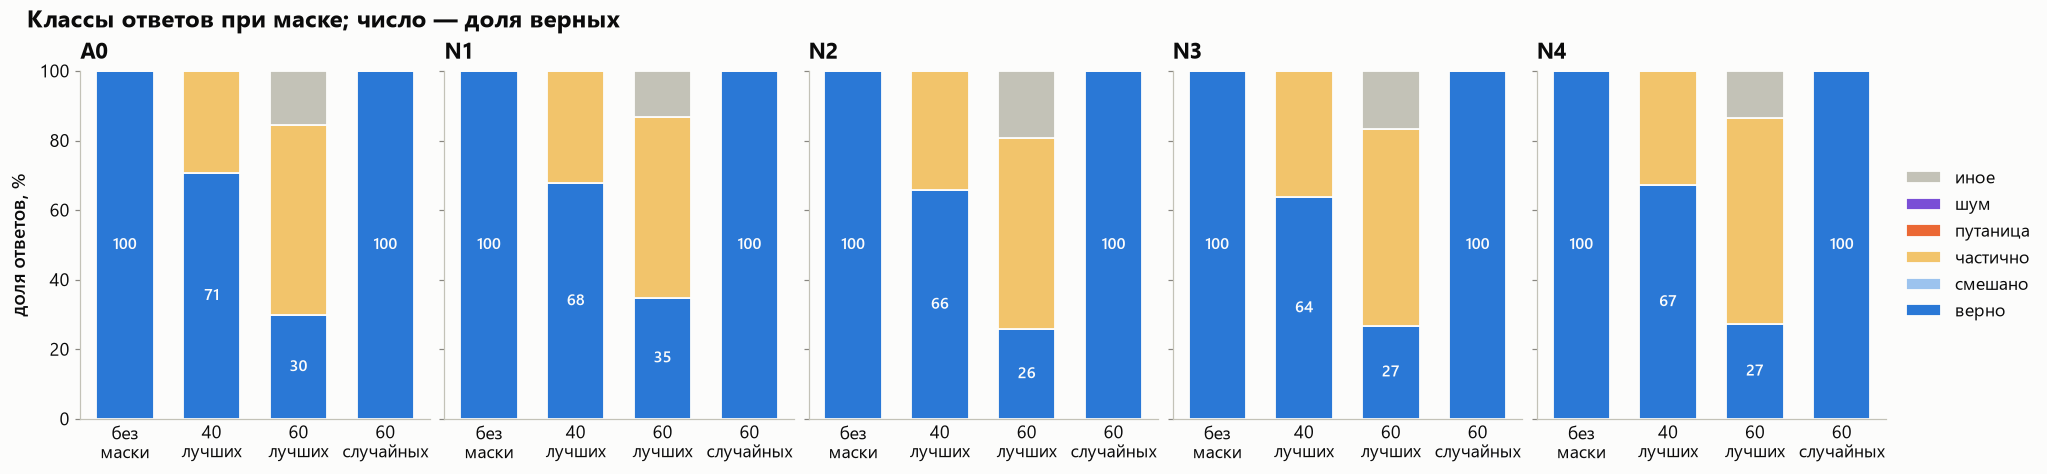

примеров  ROUGE1_больше_50  точная_фраза  верно  смешано  \
run      level                                                             
none     A0          198             100.0         100.0  100.0        0   
         N1          198             100.0         100.0  100.0        0   
         N2          198             100.0         100.0  100.0        0   
         N3          198             100.0         100.0  100.0        0   
         N4          198             100.0         100.0  100.0        0   
top40    A0          198             100.0           2.5   70.7        0   
         N1          198             100.0           2.5   67.7        0   
         N2          198             100.0           2.5   65.7        0   
         N3          198             100.0           2.5   63.6        0   
         N4          198             100.0           4.0   67.2        0   
top60    A0          198              86.9           0.0   29.8        0   
         N1          198              88.9           0.0   34.8        0   
         N2          198              87.4           0.0   25.8        0   
         N3          198              84.8           0.0   26.8        0   
         N4          198              87.4           0.0   27.3        0   
random60 A0          198             100.0          98.5  100.0        0   
         N1          198             100.0          98.5  100.0        0   
         N2          198             100.0          99.5  100.0        0   
         N3          198             100.0          99.0  100.0        0   
         N4          198             100.0          99.0  100.0        0   

                частично  путаница  шум  иное  
run      level                                 
none     A0          0.0         0    0   0.0  
         N1          0.0         0    0   0.0  
         N2          0.0         0    0   0.0  
         N3          0.0         0    0   0.0  
         N4          0.0         0    0   0.0  
top40    A0         29.3         0    0   0.0  
         N1         32.3         0    0   0.0  
         N2         34.3         0    0   0.0  
         N3         36.4         0    0   0.0  
         N4         32.8         0    0   0.0  
top60    A0         54.5         0    0  15.7  
         N1         52.0         0    0  13.1  
         N2         55.1         0    0  19.2  
         N3         56.6         0    0  16.7  
         N4         59.1         0    0  13.6  
random60 A0          0.0         0    0   0.0  
         N1          0.0         0    0   0.0  
         N2          0.0         0    0   0.0  
         N3          0.0         0    0   0.0  
         N4          0.0         0    0   0.0

In [49]:
fig, axes = plt.subplots(1, len(LEVELS), figsize=style.size(3.3 * len(LEVELS) + 2, 4.2), sharey=True)
for ax, level in zip(axes, LEVELS):
    class_bars(both[both["level"] == level], "run", RUNS, by_labels=[RUN_LABELS[r].replace(" ", "\n") for r in RUNS],
               ax=ax, legend=ax is axes[-1], title=level)
    if ax is not axes[0]:
        ax.set_ylabel("")
fig.suptitle("Классы ответов при маске; число — доля верных", x=0.01, ha="left", fontweight="bold")
show(axes, "axisN_mask_classes")

class_table(both, ["run", "level"]).loc[[(r, l) for r in RUNS for l in LEVELS]]

### 3.4. Где ломается: длина и глубина при маске 60 лучших

Карты доли верных для прогона `top60` и доля верных по длине контекста для всех прогонов (уровни N вместе).

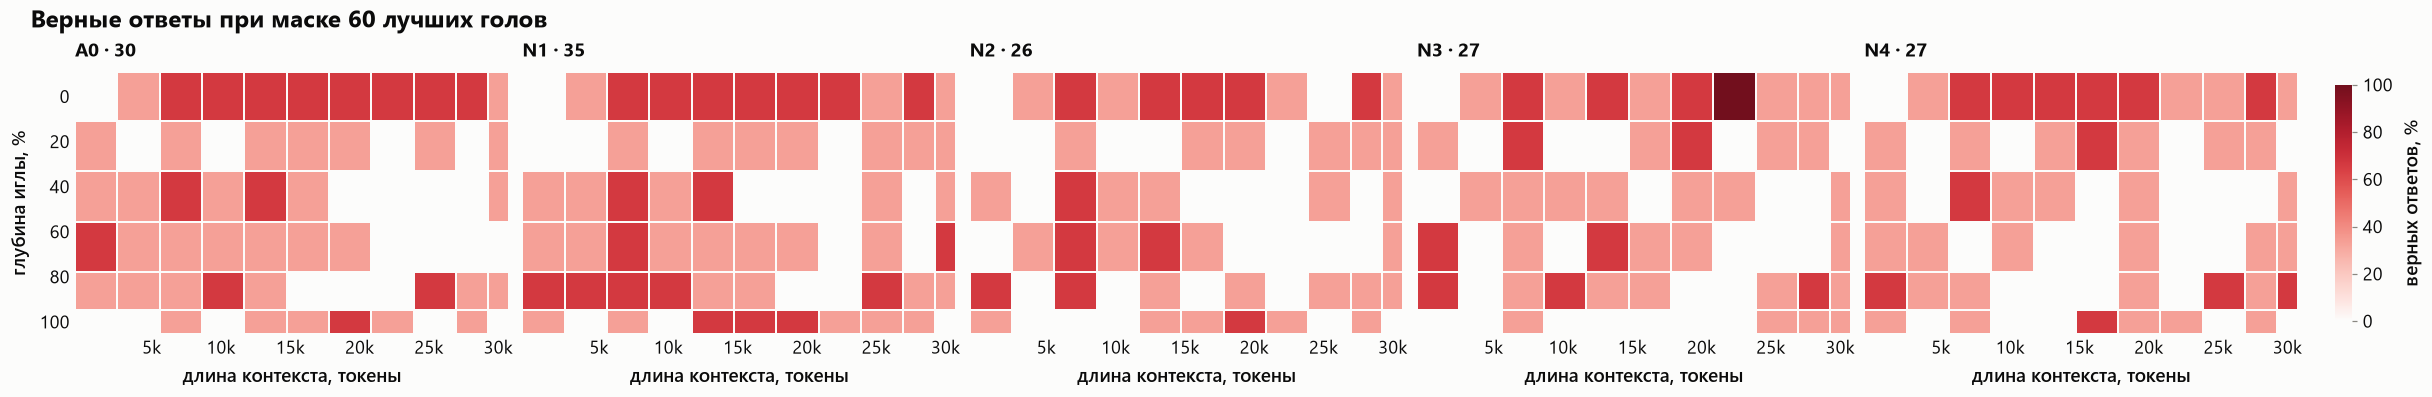

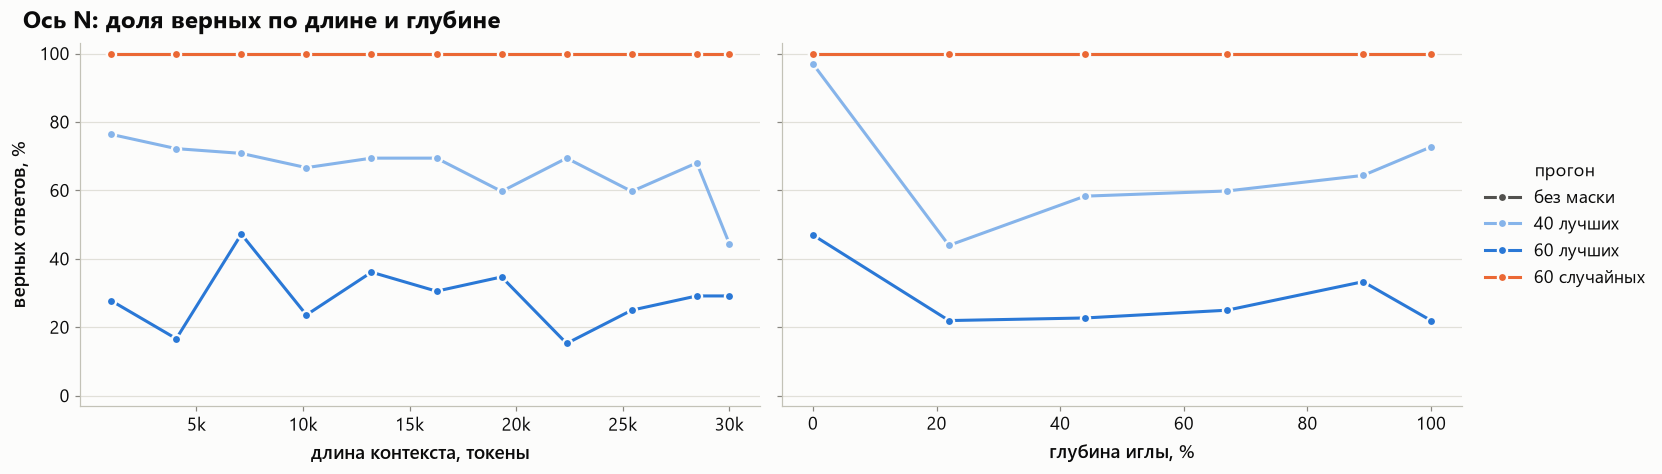

In [50]:
masked = both[both["run"] == "top60"]
show(plots.niah_grid(masked.assign(run=masked["level"]), {lv: lv for lv in LEVELS}, value="correct", columns=5,
                     title="Верные ответы при маске 60 лучших голов"), "axisN_niah_top60")

fig, axes = plt.subplots(1, 2, figsize=style.size(15, 4.2), sharey=True)
only_n = both[both["axis"] == AXIS]
for ax, x, step in zip(axes, ("context_length", "depth_percent"), (5000, 20)):
    for run in RUNS:
        line = only_n[only_n["run"] == run].groupby(x)["correct"].mean() * 100
        ax.plot(line.index, line.to_numpy(), marker="o", color=RUN_COLORS[run], label=RUN_LABELS[run])
    plots.round_axis(ax, "x", only_n[x].min(), only_n[x].max(), step, plots.thousands if x == "context_length" else None)
    ax.set_xlabel(plots.AXIS_LABELS[x])
    ax.set_ylim(-3, 103)
    plots.round_axis(ax, "y", 0, 100, 20)
axes[0].set_ylabel("верных ответов, %")
axes[-1].legend(loc="center left", bbox_to_anchor=(1.01, 0.5), title="прогон")
fig.suptitle("Ось N: доля верных по длине и глубине", x=0.01, ha="left", fontweight="bold")
show(axes, "axisN_by_length_depth")

## 4. Перефразы

Класс «верно» требует каждый факт ровно в написании из `answer_key`. При маске модель часто пишет факт **короче**: «ring the bell» вместо «brass bell», «smoked lemon» вместо «lemon peel», «door painted white» вместо «white reindeer». Такой ответ попадает в «частично», хотя по смыслу почти верен.

Здесь каждый факт ответа размечается по тому, как он записан:

| Уровень | Что это | Пример для «brass bell» |
|---|---|---|
| дословно | написание факта целиком (с формой числа) | `brass bell`, `brass bells` |
| без уточнения | осталось только главное слово | `the bell`, `a bell` |
| только признак | осталось только уточнение | `brass` |
| нет | факта в ответе нет | — |

Списки написаний (`FACT_FORMS`) собраны по ответам этих прогонов, как `vizual/paraphrase.py` для иглы про Сан-Франциско.

In [51]:
FACT_FORMS = {   # семейство -> факт -> уровень -> регулярное выражение по тексту без регистра и пунктуации
    "lisbon": {"brass bell": {"exact": r"brass bells?", "short": r"bells?", "attribute": r"brass"},
               "guest book": {"exact": r"guest ?books?|visitors? books?", "short": r"books?", "attribute": r"guests?"}},
    "cairo": {"lemon peel": {"exact": r"lemon peels?|peels? of (a )?lemons?", "short": r"lemons?", "attribute": r"peels?|zest"},
              "black clay": {"exact": r"black clay", "short": r"clay", "attribute": r"black"}},
    "oslo": {"red slate": {"exact": r"red slates?", "short": r"slates?", "attribute": r"red"},
             "white reindeer": {"exact": r"white reindeers?", "short": r"reindeers?", "attribute": r"white"}},
}
WLEVELS = ["exact", "short", "attribute", "absent"]
WLABELS = {"exact": "дословно", "short": "без уточнения", "attribute": "только признак", "absent": "нет"}
WCOLORS = {"exact": T.colors["top"], "short": "#9cc3ee", "attribute": "#f2c46b", "absent": T.colors["muted"]}


def wording(text, forms):
    """Ближайший уровень написания факта в ответе и найденная строка."""
    t = f" {plain(text)} "
    for level in WLEVELS[:-1]:
        found = re.search(rf"(?<=\s)({forms[level]})(?=\s)", t)
        if found:
            return level, found.group(1)
    return "absent", ""


for family, fs in FACT_FORMS.items():
    m = both["family"] == family
    for i, (fact, forms) in enumerate(fs.items(), 1):
        found = both.loc[m, "response"].map(lambda r: wording(r, forms))
        both.loc[m, f"fact{i}"] = found.map(lambda x: x[0])
        both.loc[m, f"fact{i}_text"] = found.map(lambda x: x[1])
        both.loc[m, f"fact{i}_name"] = fact


STRUCTURES = ["exact", "facts_exact", "facts_cut", "one_missing", "none"]
STRUCTURE_LABELS = {"exact": "точная фраза", "facts_exact": "оба факта дословно, фраза другая", "facts_cut": "оба факта есть, но усечены",
                    "one_missing": "один факт пропал", "none": "нет ни одного факта"}
STRUCTURE_COLORS = dict(zip(STRUCTURES, [T.colors["top"], "#86b4ea", "#f2c46b", T.colors["random"], T.colors["muted"]]))

def structure(row):
    levels = [row["fact1"], row["fact2"]]
    if row["exact"]:
        return "exact"
    if all(l == "exact" for l in levels):
        return "facts_exact"
    if all(l != "absent" for l in levels):
        return "facts_cut"
    return "one_missing" if any(l != "absent" for l in levels) else "none"

both["structure"] = both.apply(structure, axis=1)
both["lenient"] = both["structure"].isin(["exact", "facts_exact", "facts_cut"]) & ~both["answer_class"].isin(["noise", "mixed", "confusion"])

# строгая и мягкая доля верных: «мягко» — оба факта названы хотя бы усечённо
strict_lenient = both.groupby(["run", "level"]).agg(верно_строго=("correct", "mean"), оба_факта_хотя_бы_усечённо=("lenient", "mean")) * 100
strict_lenient.round(1).loc[[(r, l) for r in RUNS for l in LEVELS]]

верно_строго  оба_факта_хотя_бы_усечённо
run      level                                          
none     A0            100.0                       100.0
         N1            100.0                       100.0
         N2            100.0                       100.0
         N3            100.0                       100.0
         N4            100.0                       100.0
top40    A0             70.7                        98.5
         N1             67.7                        98.0
         N2             65.7                        99.0
         N3             63.6                        99.0
         N4             67.2                        99.0
top60    A0             29.8                        79.8
         N1             34.8                        80.3
         N2             25.8                        77.8
         N3             26.8                        80.3
         N4             27.3                        81.8
random60 A0            100.0                       100.0
         N1            100.0                       100.0
         N2            100.0                       100.0
         N3            100.0                       100.0
         N4            100.0                       100.0

### 4.1. Структура ответа по уровням

По панели на уровень (A0 первым), в каждой — четыре прогона. Разница между «точная фраза» и «оба факта есть, но усечены» и есть перефраз. Ниже — то же числом и сравнение строгого класса «верно» с мягким критерием «оба факта названы хотя бы усечённо».

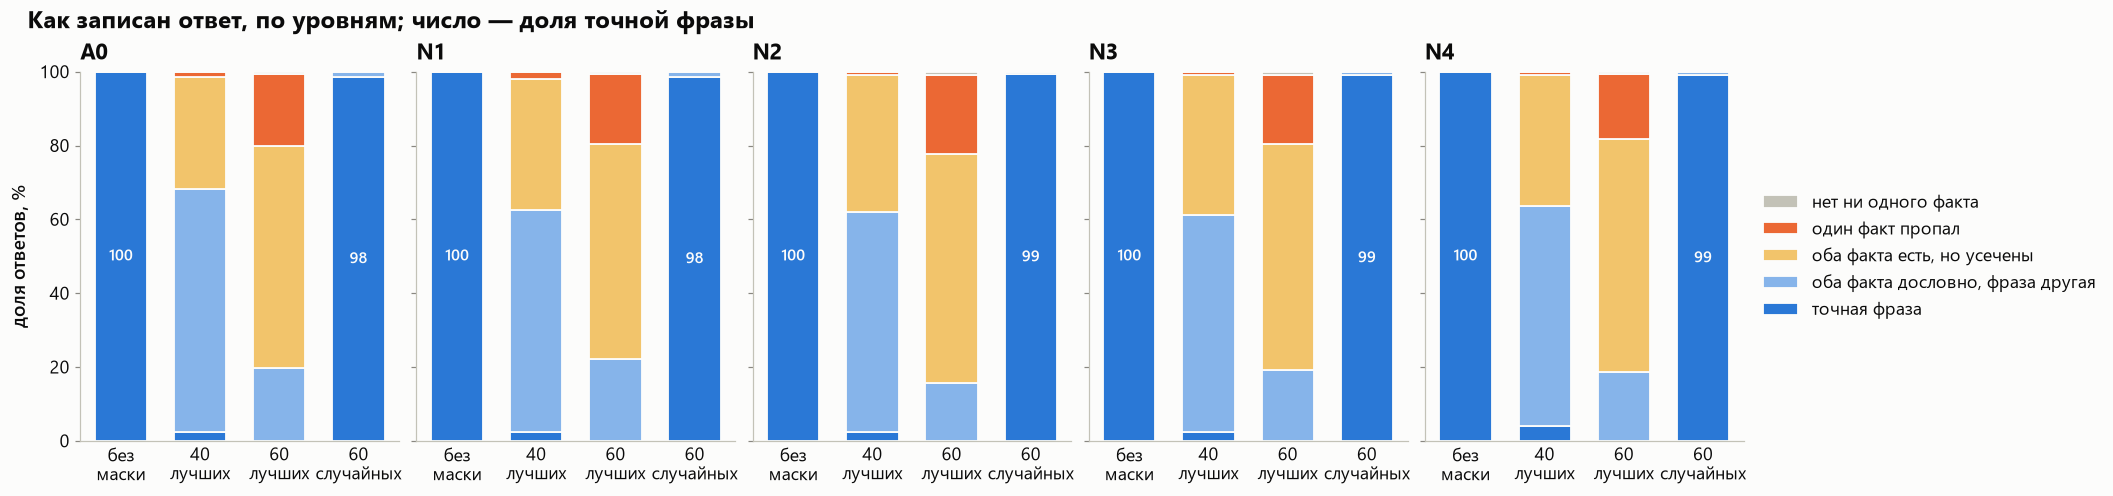

structure       точная фраза  оба факта дословно, фраза другая  \
level run                                                        
A0    none             100.0                               0.0   
      top40              2.5                              65.7   
      top60              0.0                              19.7   
      random60          98.5                               1.5   
N1    none             100.0                               0.0   
      top40              2.5                              60.1   
      top60              0.0                              22.2   
      random60          98.5                               1.5   
N2    none             100.0                               0.0   
      top40              2.5                              59.6   
      top60              0.0                              15.7   
      random60          99.5                               0.5   
N3    none             100.0                               0.0   
      top40              2.5                              58.6   
      top60              0.0                              19.2   
      random60          99.0                               1.0   
N4    none             100.0                               0.0   
      top40              4.0                              59.6   
      top60              0.0                              18.7   
      random60          99.0                               1.0   

structure       оба факта есть, но усечены  один факт пропал  \
level run                                                      
A0    none                             0.0               0.0   
      top40                           30.3               1.5   
      top60                           60.1              19.7   
      random60                         0.0               0.0   
N1    none                             0.0               0.0   
      top40                           35.4               2.0   
      top60                           58.1              19.2   
      random60                         0.0               0.0   
N2    none                             0.0               0.0   
      top40                           36.9               1.0   
      top60                           62.1              21.2   
      random60                         0.0               0.0   
N3    none                             0.0               0.0   
      top40                           37.9               1.0   
      top60                           61.1              18.7   
      random60                         0.0               0.0   
N4    none                             0.0               0.0   
      top40                           35.4               1.0   
      top60                           63.1              17.7   
      random60                         0.0               0.0   

structure       нет ни одного факта  
level run                            
A0    none                      0.0  
      top40                     0.0  
      top60                     0.5  
      random60                  0.0  
N1    none                      0.0  
      top40                     0.0  
      top60                     0.5  
      random60                  0.0  
N2    none                      0.0  
      top40                     0.0  
      top60                     1.0  
      random60                  0.0  
N3    none                      0.0  
      top40                     0.0  
      top60                     1.0  
      random60                  0.0  
N4    none                      0.0  
      top40                     0.0  
      top60                     0.5  
      random60                  0.0

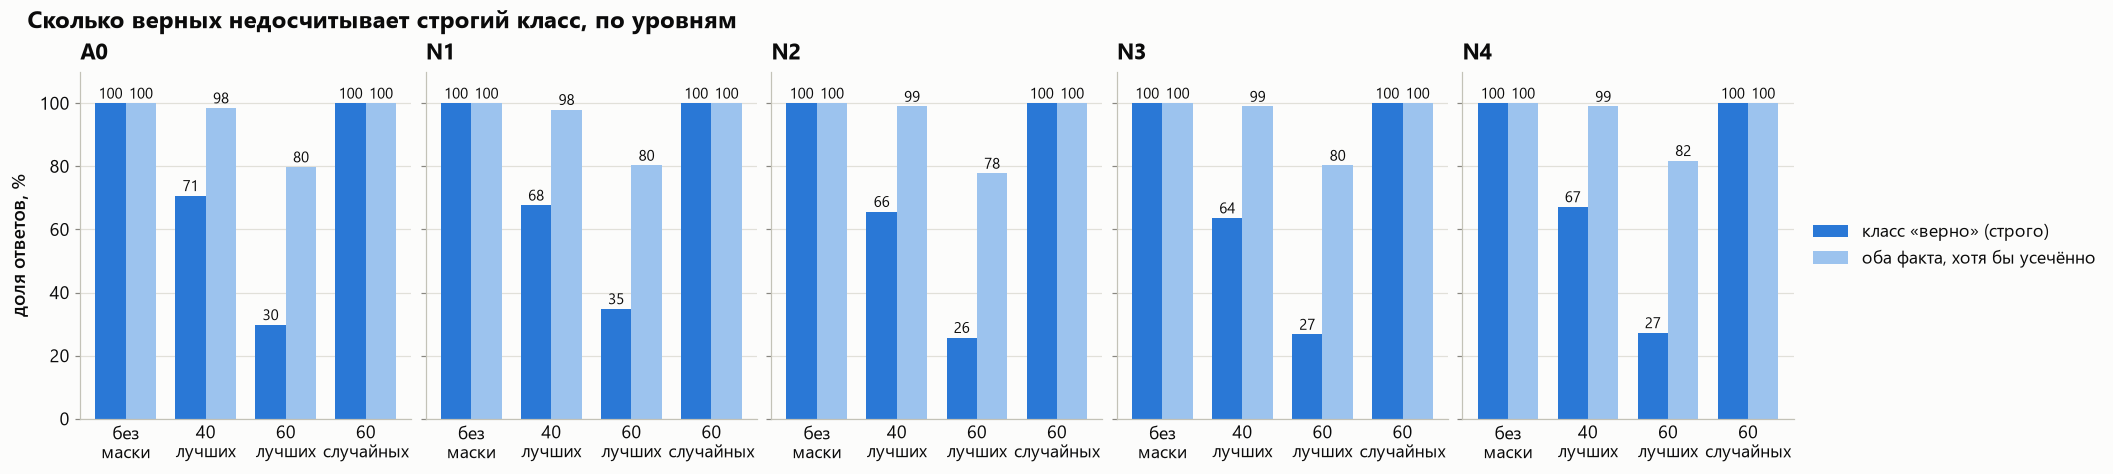

In [52]:
fig, axes = plt.subplots(1, len(LEVELS), figsize=style.size(3.3 * len(LEVELS) + 2.6, 4.4), sharey=True)
for ax, level in zip(axes, LEVELS):
    stacked(both[both["level"] == level], "structure", STRUCTURES, STRUCTURE_LABELS, STRUCTURE_COLORS, "run", RUNS,
            by_labels=[RUN_LABELS[r].replace(" ", "\n") for r in RUNS], ax=ax, legend=ax is axes[-1], title=level, annotate="exact")
    if ax is not axes[0]:
        ax.set_ylabel("")
fig.suptitle("Как записан ответ, по уровням; число — доля точной фразы", x=0.01, ha="left", fontweight="bold")
show(axes, "axisN_structure_levels")

# числом: доли структур по уровню и прогону, %
display(both.groupby(["level", "run"])["structure"].value_counts(normalize=True).unstack(fill_value=0)
            .reindex(columns=STRUCTURES, fill_value=0).mul(100).round(1).rename(columns=STRUCTURE_LABELS)
            .loc[[(l, r) for l in LEVELS for r in RUNS]])

# строгий класс против «оба факта, хотя бы усечённо» — по уровням и прогонам
fig, axes = plt.subplots(1, len(LEVELS), figsize=style.size(3.3 * len(LEVELS) + 2.6, 4.2), sharey=True)
width = 0.38
xs = np.arange(len(RUNS))
for ax, level in zip(axes, LEVELS):
    part = strict_lenient.xs(level, level="level").reindex(RUNS)
    ax.bar(xs - width / 2, part["верно_строго"], width=width, color=T.colors["top"], label="класс «верно» (строго)")
    ax.bar(xs + width / 2, part["оба_факта_хотя_бы_усечённо"], width=width, color="#9cc3ee", label="оба факта, хотя бы усечённо")
    for x, (s, l) in zip(xs, part[["верно_строго", "оба_факта_хотя_бы_усечённо"]].to_numpy()):
        ax.annotate(f"{s:.0f}", (x - width / 2, s), xytext=(0, 3), textcoords="offset points", ha="center", fontsize=T.font - 2)
        ax.annotate(f"{l:.0f}", (x + width / 2, l), xytext=(0, 3), textcoords="offset points", ha="center", fontsize=T.font - 2)
    ax.set_xticks(xs, [RUN_LABELS[r].replace(" ", "\n") for r in RUNS])
    ax.tick_params(axis="x", length=0)
    ax.set_ylim(0, 110)
    plots.round_axis(ax, "y", 0, 100, 20)
    plots.titles(ax, level)
axes[0].set_ylabel("доля ответов, %")
axes[-1].legend(loc="center left", bbox_to_anchor=(1.01, 0.5))
fig.suptitle("Сколько верных недосчитывает строгий класс, по уровням", x=0.01, ha="left", fontweight="bold")
show(axes, "axisN_strict_vs_lenient")

### 4.2. Каждый факт отдельно

По панели на факт: как он записан в четырёх прогонах (уровни N вместе). Видно, какой факт теряется первым и как именно: уточнение или главное слово.

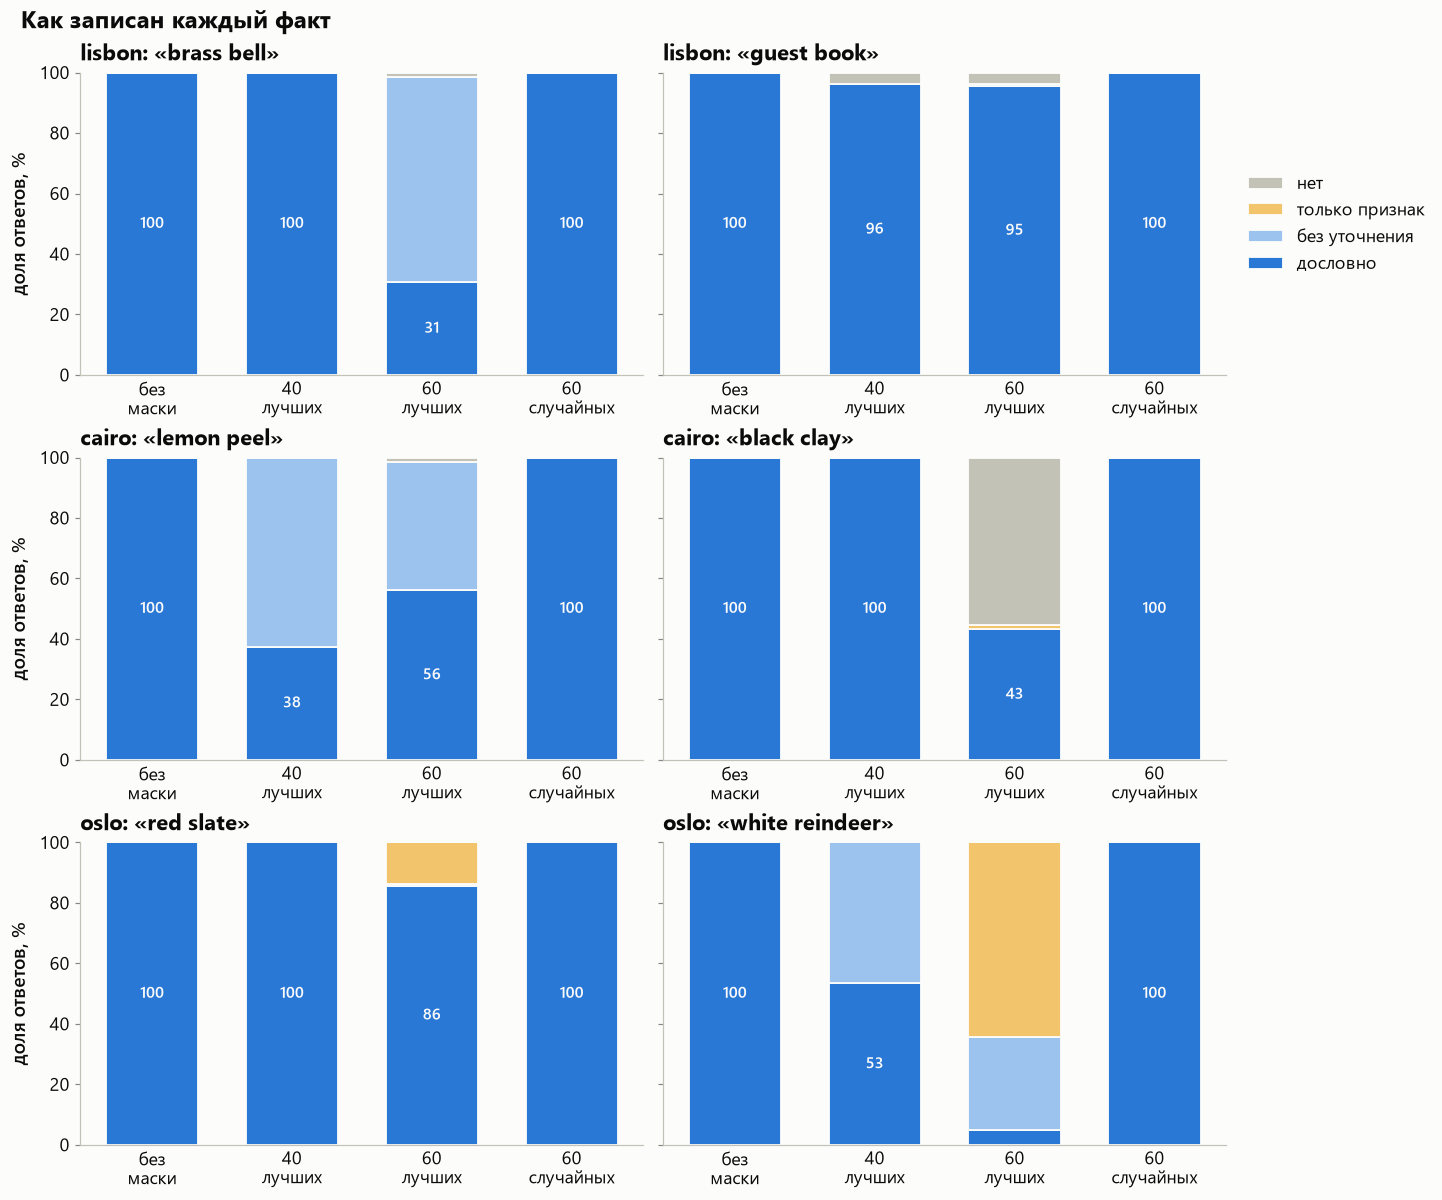

In [53]:
only_n = both[both["axis"] == AXIS]
fig, axes = plt.subplots(len(FACT_FORMS), 2, figsize=style.size(13, 3.6 * len(FACT_FORMS)), sharey=True)
for row, (family, fs) in zip(axes, FACT_FORMS.items()):
    part = only_n[only_n["family"] == family]
    for ax, (i, fact) in zip(row, enumerate(fs, 1)):
        stacked(part, f"fact{i}", WLEVELS, WLABELS, WCOLORS, "run", RUNS, by_labels=[RUN_LABELS[r].replace(" ", "\n") for r in RUNS],
                ax=ax, legend=ax is axes[0, -1], title=f"{family}: «{fact}»", annotate="exact")
        if ax is not row[0]:
            ax.set_ylabel("")
fig.suptitle("Как записан каждый факт", x=0.01, ha="left", fontweight="bold")
show(axes, "axisN_fact_wordings")

### 4.3. Что именно написано вместо факта

Самые частые написания на уровнях «без уточнения» и «только признак» и по два примера ответа на каждый вид структуры.

In [54]:
rows = []
for i in (1, 2):
    part = only_n[only_n[f"fact{i}"].isin(["short", "attribute"])]
    for (name, level, text), g in part.groupby([f"fact{i}_name", f"fact{i}", f"fact{i}_text"]):
        rows.append({"факт": name, "уровень": WLABELS[level], "написано": text, "ответов": len(g),
                     "из них в прогонах": ", ".join(f"{RUN_LABELS[r]} {n}" for r, n in g["run"].value_counts().items())})
display(pd.DataFrame(rows).sort_values(["факт", "ответов"], ascending=[True, False]).groupby("факт").head(4).set_index(["факт", "уровень"]))

pd.set_option("display.max_colwidth", 300)
examples = only_n[only_n["structure"] != "exact"].sort_values("n_tokens").groupby(["structure", "family"]).head(1)
examples.assign(структура=examples["structure"].map(STRUCTURE_LABELS)).set_index(["структура", "family"])[
    ["level", "run", "answer_class", "rouge1_recall", "response"]].round(0)

написано  ответов             из них в прогонах
факт           уровень                                                        
black clay     только признак     black        4                   60 лучших 4
brass bell     без уточнения       bell      179                 60 лучших 179
guest book     без уточнения       book        2                   60 лучших 2
lemon peel     без уточнения      lemon      277  40 лучших 165, 60 лучших 112
red slate      только признак       red       36                  60 лучших 36
               без уточнения      slate        2                   60 лучших 2
white reindeer без уточнения   reindeer      204   40 лучших 123, 60 лучших 81
               только признак     white      170                 60 лучших 170

,,level,run,answer_class,rouge1_recall,response
структура,family,,,,,
"оба факта есть, но усечены",oslo,N3,top60,other,54.0,The oldest house in Oslo has a red roof and a white door.
"оба факта дословно, фраза другая",oslo,N4,random60,correct,92.0,The oldest house in Oslo has a red slate roof and a door painted with a white reindeer.
"оба факта есть, но усечены",lisbon,N1,top60,partial,50.0,Every visitor to the Lisbon Tram Museum is asked to ring a bell and sign a guest book.
один факт пропал,cairo,N3,top60,other,77.0,The famous soup of the Zahira Cafe in Cairo is cooked with smoked lemon and served in a bowl.
"оба факта дословно, фраза другая",lisbon,N3,top60,correct,62.0,Every visitor to the Lisbon Tram Museum is asked to ring a brass bell and sign the guest book.
"оба факта есть, но усечены",cairo,N4,top60,other,85.0,The famous soup of the Zahira Cafe in Cairo is cooked with smoked lemon and served in a black bowl.
один факт пропал,lisbon,N4,top60,other,31.0,"Based on the content provided, every visitor to the Lisbon Tram Museum is asked to **ring a bell**."
"оба факта дословно, фраза другая",cairo,N3,top40,correct,100.0,The famous soup of the Zahira in Cairo is cooked with smoked lemon peel and served in a bowl made of black clay.
нет ни одного факта,cairo,N2,top60,other,23.0,"The famous soup of the Zahira Cafe in Cairo is not directly mentioned in the text. However, the passage discusses how technological progress has led to the creation of more addictive substances and activities, and it suggests that the process of making things more addictive is accelerating. The ..."


## 5. Куда смотрят головы

Прогон без маски сохранил внимание. По каждому уровню для 20 лучших голов детекции и для всех голов:

| Метрика | Что это |
|---|---|
| `needle_sentence_mass` | доля внимания на предложении-игле, среднее по шагам ответа |
| `competing_mass` | доля внимания на всех шумовых вставках вместе |
| `competing_max_mass` | на самой «притягательной» из них |
| `copy_count` | копирование ответа из иглы |
| `copy_competing` | копирование из шумовых вставок |

Иглы и вставки разной длины (вставки длиннее), поэтому рядом показана **плотность** — масса, делённая на длину участка в токенах: она отвечает, смотрит ли голова на токен шума сильнее, чем на токен иглы.

In [55]:
ATT = ["copy_count", "needle_sentence_mass", "competing_mass", "competing_max_mass", "copy_competing"]

def load_heads(axis, levels):
    """Метрики голов прогона без маски для нужных уровней: таблица примеров и {метрика: [пример, слой, голова]}."""
    out = data.path(f"{RUNS_DIR}/{axis}/none")
    samples = both[(both["axis"] == axis) & (both["run"] == "none") & both["level"].isin(levels)]
    keep, arrays = [], {m: [] for m in ATT}
    for i, sample_id in zip(samples.index, samples["id"]):
        p = os.path.join(out, "heads", f"{sample_id}.npz")
        if not os.path.exists(p):
            continue
        with np.load(p) as d:
            for m in ATT:
                arrays[m].append(d[m] if m in d.files else np.full((len(LAYERS), N_HEADS), np.nan, dtype=np.float32))
        keep.append(i)
    return samples.loc[keep].reset_index(drop=True), {m: np.stack(v) for m, v in arrays.items()}

a0_samples, a0_arrays = load_heads("A", ["A0"])
n_samples, n_arrays = load_heads(AXIS, LEVELS[1:])
head_samples = pd.concat([a0_samples, n_samples], ignore_index=True)
head_arrays = {m: np.concatenate([a0_arrays[m], n_arrays[m]]) for m in ATT}

detect_score = data.head_score_file(RANKING, LAYERS, N_HEADS)
chosen = np.zeros_like(detect_score, dtype=bool)
chosen.flat[np.argsort(-detect_score.ravel(), kind="stable")[:TOP]] = True

# длины участков для плотности — в словах (иглы и вставки из файлов данных); у обоих участков одна мера, поэтому отношение плотностей корректно
INSERT_WORDS = {lv: np.mean([sum(len(inserts[f]["inserts"][n]["text"].split()) for n in inserts[f]["levels"][lv]["use"]) for f in FAMILIES])
                for lv in LEVELS[1:]}
NEEDLE_WORDS = np.mean([len(needles[f]["needle"].split()) for f in FAMILIES])

rows = []
for level in LEVELS:
    idx = (head_samples["level"] == level).to_numpy()
    for heads_name, sel in ((f"{TOP} лучших", chosen), ("все головы", np.ones_like(chosen))):
        row = {"level": level, "головы": heads_name, "примеров": int(idx.sum())}
        for m in ATT:
            row[m] = float(np.nanmean(head_arrays[m][idx][:, sel]))
        row["плотность игла / шум"] = (row["needle_sentence_mass"] / NEEDLE_WORDS) / (row["competing_mass"] / INSERT_WORDS[level]) \
            if level != "A0" and row["competing_mass"] > 0 else np.nan
        rows.append(row)
attention = pd.DataFrame(rows)
attention.set_index(["головы", "level"]).round(4)

,,примеров,copy_count,needle_sentence_mass,competing_mass,competing_max_mass,copy_competing,плотность игла / шум
головы,level,,,,,,,
20 лучших,A0,198,0.6794,0.4050,0.0000,0.0000,0.0000,NaN
все головы,A0,198,0.0278,0.0565,0.0000,0.0000,0.0000,NaN
20 лучших,N1,198,0.6833,0.4044,0.0017,0.0017,0.0000,269.0227
все головы,N1,198,0.0277,0.0563,0.0016,0.0016,0.0000,38.2255
20 лучших,N2,198,0.6854,0.4056,0.0045,0.0045,0.0001,98.7390
все головы,N2,198,0.0279,0.0561,0.0035,0.0035,0.0001,17.6988
20 лучших,N3,198,0.6894,0.4128,0.0122,0.0081,0.0001,104.8001
все головы,N3,198,0.0283,0.0566,0.0078,0.0049,0.0001,22.3316
20 лучших,N4,198,0.6869,0.4056,0.0094,0.0094,0.0001,45.8861


### 5.1. Игла против шума

Слева — масса внимания на игле и на шуме у 20 лучших голов (штрих — на игле у всех голов); справа — во сколько раз плотность внимания на токен иглы выше, чем на токен шума (ось логарифмическая; 1 — одинаково).

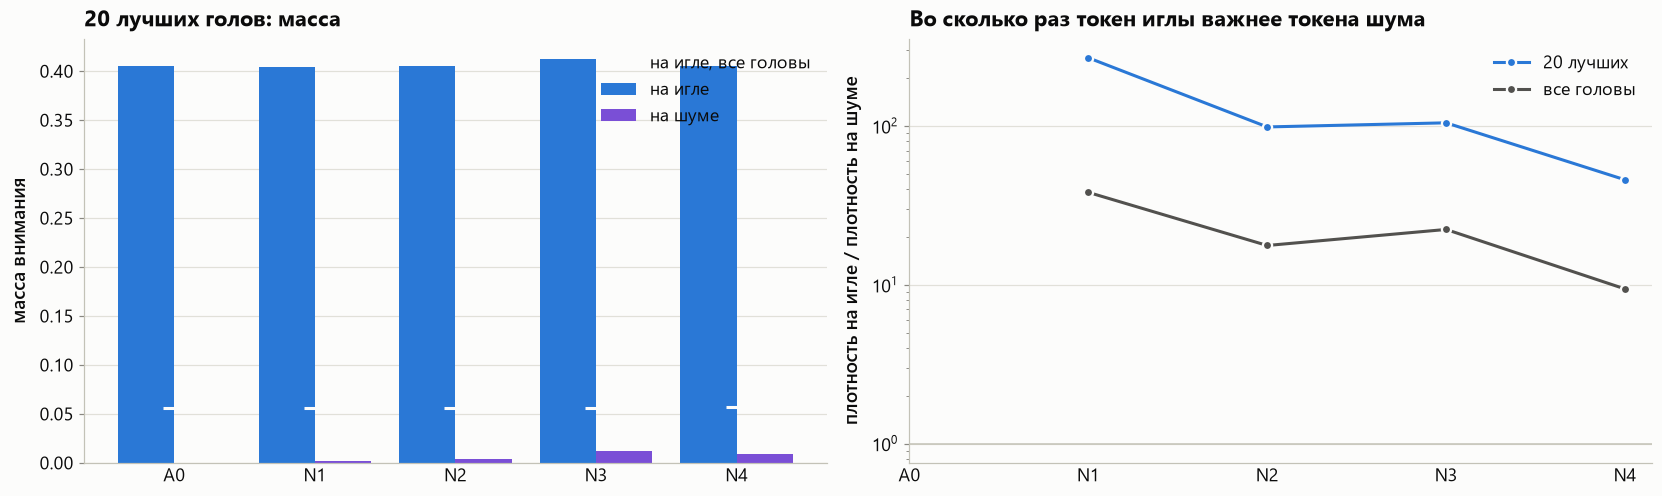

In [56]:
top = attention[attention["головы"] == f"{TOP} лучших"].set_index("level").reindex(LEVELS)
rest = attention[attention["головы"] == "все головы"].set_index("level").reindex(LEVELS)
xs = np.arange(len(LEVELS))
fig, axes = plt.subplots(1, 2, figsize=style.size(15, 4.4))
axes[0].bar(xs - 0.2, top["needle_sentence_mass"], width=0.4, color=T.colors["top"], label="на игле")
axes[0].bar(xs + 0.2, top["competing_mass"].fillna(0), width=0.4, color=CLASS_COLORS["noise"], label="на шуме")
axes[0].plot(xs, rest["needle_sentence_mass"], "_", color=T.ink, markersize=14, mew=2, label="на игле, все головы")
axes[0].set_ylabel("масса внимания")
plots.titles(axes[0], f"{TOP} лучших голов: масса")
for name, color in ((f"{TOP} лучших", T.colors["top"]), ("все головы", T.colors["none"])):
    part = attention[attention["головы"] == name].set_index("level").reindex(LEVELS)
    axes[1].plot(xs[1:], part["плотность игла / шум"].iloc[1:], marker="o", color=color, label=name)
axes[1].axhline(1, color=T.axis, linewidth=1)
axes[1].set_yscale("log")
axes[1].set_ylabel("плотность на игле / плотность на шуме")
plots.titles(axes[1], "Во сколько раз токен иглы важнее токена шума")
for ax in axes:
    ax.set_xticks(xs, LEVELS)
    ax.tick_params(axis="x", length=0)
    ax.legend(loc="best")
show(axes, "axisN_attention")

### 5.2. Какие головы смотрят на шум

Карта массы внимания на шуме для каждой головы (уровни N вместе); кружками отмечены 20 лучших голов детекции. Ниже — 15 голов, сильнее всех смотрящих на шум, и есть ли среди них retrieval-головы.

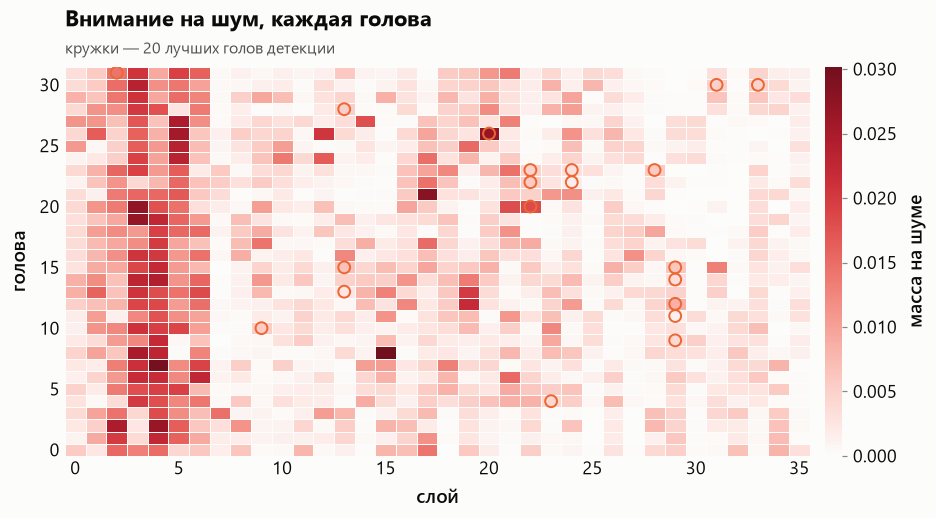

,голова,масса на шуме,масса на игле,место в рейтинге copy_count
0,15-8,0.0302,0.2611,71
1,4-7,0.0297,0.0304,207
2,17-21,0.0281,0.3721,69
3,3-20,0.0272,0.0109,302
4,3-19,0.0271,0.0255,279
5,20-26,0.0269,0.3328,6
6,4-2,0.0266,0.0115,349
7,5-26,0.0254,0.0089,350
8,3-8,0.0250,0.0406,232
9,5-27,0.0247,0.0085,315


In [57]:
idx = (head_samples["axis"] == AXIS).to_numpy()
noise_score = np.nanmean(head_arrays["competing_mass"][idx], axis=0)
needle_score = np.nanmean(head_arrays["needle_sentence_mass"][idx], axis=0)
marks = [(LAYERS[i // N_HEADS], i % N_HEADS) for i in np.flatnonzero(chosen.ravel())]
show(plots.head_heatmap(noise_score, LAYERS, mark=marks, label="масса на шуме", title="Внимание на шум, каждая голова",
                        subtitle=f"кружки — {TOP} лучших голов детекции"), "axisN_noise_heads")

order = np.argsort(-noise_score.ravel(), kind="stable")[:15]
detect_rank = {h: r for r, h in enumerate(np.argsort(-detect_score.ravel(), kind="stable"), 1)}
pd.DataFrame({"голова": [f"{LAYERS[i // N_HEADS]}-{i % N_HEADS}" for i in order], "масса на шуме": noise_score.ravel()[order],
              "масса на игле": needle_score.ravel()[order], "место в рейтинге copy_count": [detect_rank[i] for i in order]}).round(4)

## 6. Остаются ли лучшие головы лучшими

На каждом уровне рейтинг строится заново по `copy_count` на верных ответах и сравнивается с рейтингом детекции: общие головы среди 20 лучших и Спирмен по всем головам. Пунктир — пересечение двух случайных рейтингов (≈ 0.35).

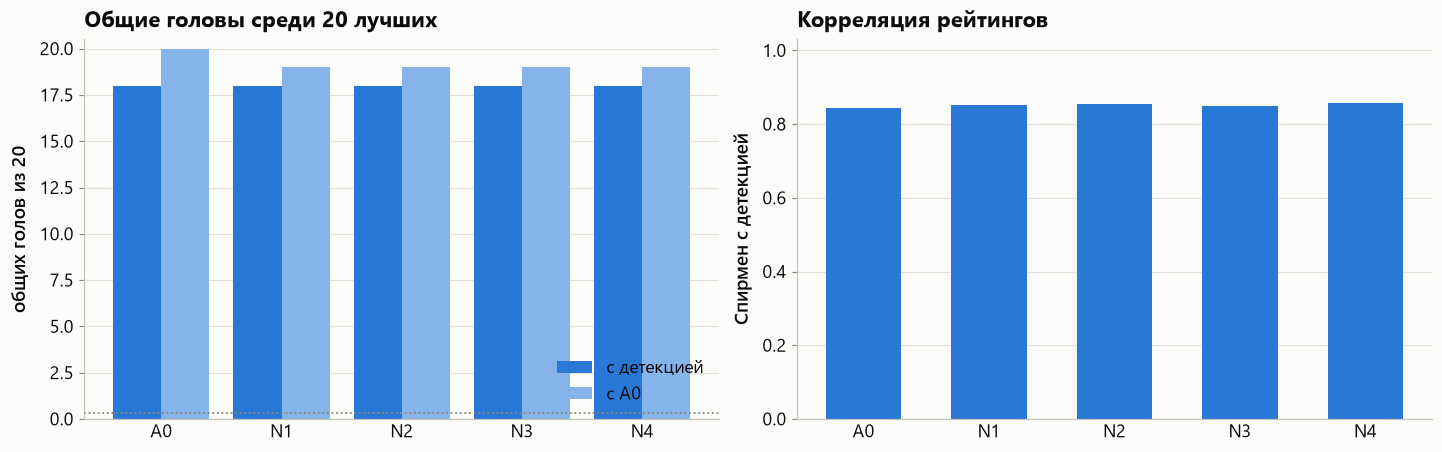

,верных примеров,общих в top-20,Спирмен,общих в top-20 с A0
level,,,,
A0,198,18,0.843,20
N1,198,18,0.853,19
N2,198,18,0.855,19
N3,198,18,0.849,19
N4,198,18,0.856,19


In [58]:
rows = []
for level in LEVELS:
    idx = ((head_samples["level"] == level) & (head_samples["answer_class"] == "correct")).to_numpy()
    if idx.sum() < 5:
        continue
    score = np.nanmean(head_arrays["copy_count"][idx], axis=0)
    rows.append({"level": level, "верных примеров": int(idx.sum()), f"общих в top-{TOP}": data.top_overlap(score, detect_score, TOP),
                 "Спирмен": data.spearman(score, detect_score), "общих в top-20 с A0": None})
stable = pd.DataFrame(rows).set_index("level")
a0_idx = ((head_samples["level"] == "A0") & (head_samples["answer_class"] == "correct")).to_numpy()
a0_score = np.nanmean(head_arrays["copy_count"][a0_idx], axis=0)
for level in stable.index:
    idx = ((head_samples["level"] == level) & (head_samples["answer_class"] == "correct")).to_numpy()
    stable.loc[level, "общих в top-20 с A0"] = data.top_overlap(np.nanmean(head_arrays["copy_count"][idx], axis=0), a0_score, TOP)

fig, axes = plt.subplots(1, 2, figsize=style.size(13, 4.0))
levels = list(stable.index)
axes[0].bar(np.arange(len(levels)) - 0.2, stable[f"общих в top-{TOP}"], width=0.4, color=T.colors["top"], label="с детекцией")
axes[0].bar(np.arange(len(levels)) + 0.2, stable["общих в top-20 с A0"].astype(float), width=0.4, color="#86b4ea", label="с A0")
axes[0].axhline(TOP * TOP / detect_score.size, color=T.ink_muted, linestyle=(0, (1, 1.5)), linewidth=1.2)
axes[0].set_ylim(0, TOP + 0.5)
axes[0].set_ylabel(f"общих голов из {TOP}")
axes[0].legend(loc="lower right")
plots.titles(axes[0], f"Общие головы среди {TOP} лучших")
axes[1].bar(range(len(levels)), stable["Спирмен"], width=0.6, color=T.colors["top"])
axes[1].set_ylim(0, 1.03)
axes[1].set_ylabel("Спирмен с детекцией")
plots.titles(axes[1], "Корреляция рейтингов")
for ax in axes:
    ax.set_xticks(range(len(levels)), levels)
    ax.tick_params(axis="x", length=0)
show(axes, "axisN_ranking")
stable.round(3)

## 7. Выводы и особенности

Ячейка ниже собирает ключевые числа из таблиц выше — по ним проверяются выводы. Сами выводы записаны по сводкам прогонов (`summary.json`) и просмотру ответов; уточнения по уровням — после выполнения ноутбука.

### Выводы

1. **Шум на модель без маски не действует.** На всех уровнях N без маски 792 из 792 ответов содержат эталонную фразу дословно — как на A0, где по `RUNS.md` все три семейства дают 100% верных. Ни расстояние до шума, ни три факта сразу, ни совпадение города (N4) ответ не портят.
2. **Шум не проникает в ответы даже при маске.** При отключении 60 лучших голов классов «шум» и «путаница» нет ни одного (по `summary.json`: верно 227, частично 441, иное 124 из 792). Ослабленная модель теряет детали иглы или отвечает не по игле, но новость о метеорите не пересказывает.
3. **Лучшие головы на шум почти не смотрят.** У 20 лучших голов масса внимания на игле на уровнях N та же, что на A0 (около 0.40–0.41), а на шуме — 0.002–0.012; копирования из шума нет совсем (`copy_competing` = 0). Сильнее всех на шум смотрят в основном головы ранних слоёв (2–6), но и у них масса не выше 0.03; среди них одна retrieval-голова из 20 лучших — 20-26 (раздел 5.2).
4. **Маска лучших голов вредит, маска случайных — нет.** 60 случайных голов: 784 из 792 ответов дословные. 40 лучших: ROUGE-1 > 50 у всех, но дословная фраза только в 23 ответах. 60 лучших: строго верных 28.7%. Насколько это совпадает с A0 при той же маске — раздел 3.2.

**Итог по оси.** В этой постановке ось N — отрицательный контроль: яркость постороннего факта не перетягивает ни ответ, ни внимание retrieval-голов. Это согласуется с тем, что retrieval-головы выбирают участок по связи с вопросом, а не по заметности текста.

### Особенности

- **Перефраз при маске — это усечение фактов.** Модель отбрасывает уточнение: «ring **the bell**» вместо «brass bell», «smoked **lemon**» вместо «lemon peel», «served in **a bowl**» вместо «bowl of black clay», «door painted **white**» вместо «white reindeer». Строгий класс считает такие ответы «частичными», поэтому доля верных при маске занижена; насколько — раздел 4.1.
- **Склейка фактов.** Встречаются ответы, где куски двух фактов соединены неверно: «sign **a green pen**» (Lisbon) — глагол из одного факта, предмет из другого.
- **Уход в стог.** Часть ответов «иное» при маске — пересказ эссе вместо ответа: «the soup … is not directly mentioned in the text. However, the book discusses…».
- **ROUGE обманчив и здесь.** При маске 40 лучших ROUGE-1 > 50 у всех 792 ответов, хотя точной фразы почти нет: усечённые ответы сохраняют большинство слов эталона.
- **Семейства теряют разные факты:** у Oslo чаще пропадает «white reindeer» (остаётся «painted white»), у Cairo — «lemon peel» и «black clay» (остаются «lemon» и «bowl»), у Lisbon — уточнение «brass». Сравнивать уровни нужно внутри семейства.
- **Ограничения:** одна точка контроля (60 случайных голов, один seed); шум по длине больше иглы, поэтому массу на шуме нужно читать вместе с плотностью (раздел 5.1); длины участков для плотности оценены по числу слов, а не токенов.

In [59]:
key = pd.DataFrame({
    "верно строго, без маски": by_run[by_run["run"] == "none"].set_index("level")["correct"],
    "верно строго, 60 лучших": by_run[by_run["run"] == "top60"].set_index("level")["correct"],
    "верно строго, 60 случайных": by_run[by_run["run"] == "random60"].set_index("level")["correct"],
    "оба факта хотя бы усечённо, 60 лучших": strict_lenient.loc["top60", "оба_факта_хотя_бы_усечённо"],
    "слова шума в ответах, любой прогон, %": both.groupby("level")["noise_leak"].mean() * 100,
    "масса на игле, 20 лучших": top["needle_sentence_mass"],
    "масса на шуме, 20 лучших": top["competing_mass"],
    f"общих в top-{TOP} с детекцией": stable[f"общих в top-{TOP}"],
}).reindex(LEVELS)
key.round(3)

,"верно строго, без маски","верно строго, 60 лучших","верно строго, 60 случайных","оба факта хотя бы усечённо, 60 лучших","слова шума в ответах, любой прогон, %","масса на игле, 20 лучших","масса на шуме, 20 лучших",общих в top-20 с детекцией
level,,,,,,,,
A0,100.0,29.798,100.0,79.798,0.0,0.405,0.000,18
N1,100.0,34.848,100.0,80.303,0.0,0.404,0.002,18
N2,100.0,25.758,100.0,77.778,0.0,0.406,0.005,18
N3,100.0,26.768,100.0,80.303,0.0,0.413,0.012,18
N4,100.0,27.273,100.0,81.818,0.0,0.406,0.009,18


## 8. Распределение внимания голов по уровням

Как меняется внимание **всех 1152 голов**, когда к игле добавляется шум. Для каждой головы — средняя масса внимания по примерам уровня (прогон без маски): `needle_sentence_mass` — на игле, `competing_mass` — на шуме. Кружками отмечены 20 лучших голов детекции.

| Рисунок | Что показывает |
|---|---|
| 8.1 | карта «слой × голова» массы на игле на каждом уровне, общая шкала |
| 8.2 | разность «уровень − A0»: какие головы теряют внимание к игле (синие) и какие набирают (красные) |
| 8.3 | масса на шуме по уровням N |
| 8.4 | головы по убыванию массы на игле; средняя масса на игле и на шуме по слоям |

Если шум не мешает, карты 8.1 совпадают с A0, а разности 8.2 близки к нулю. В конце — сводная таблица по уровням.

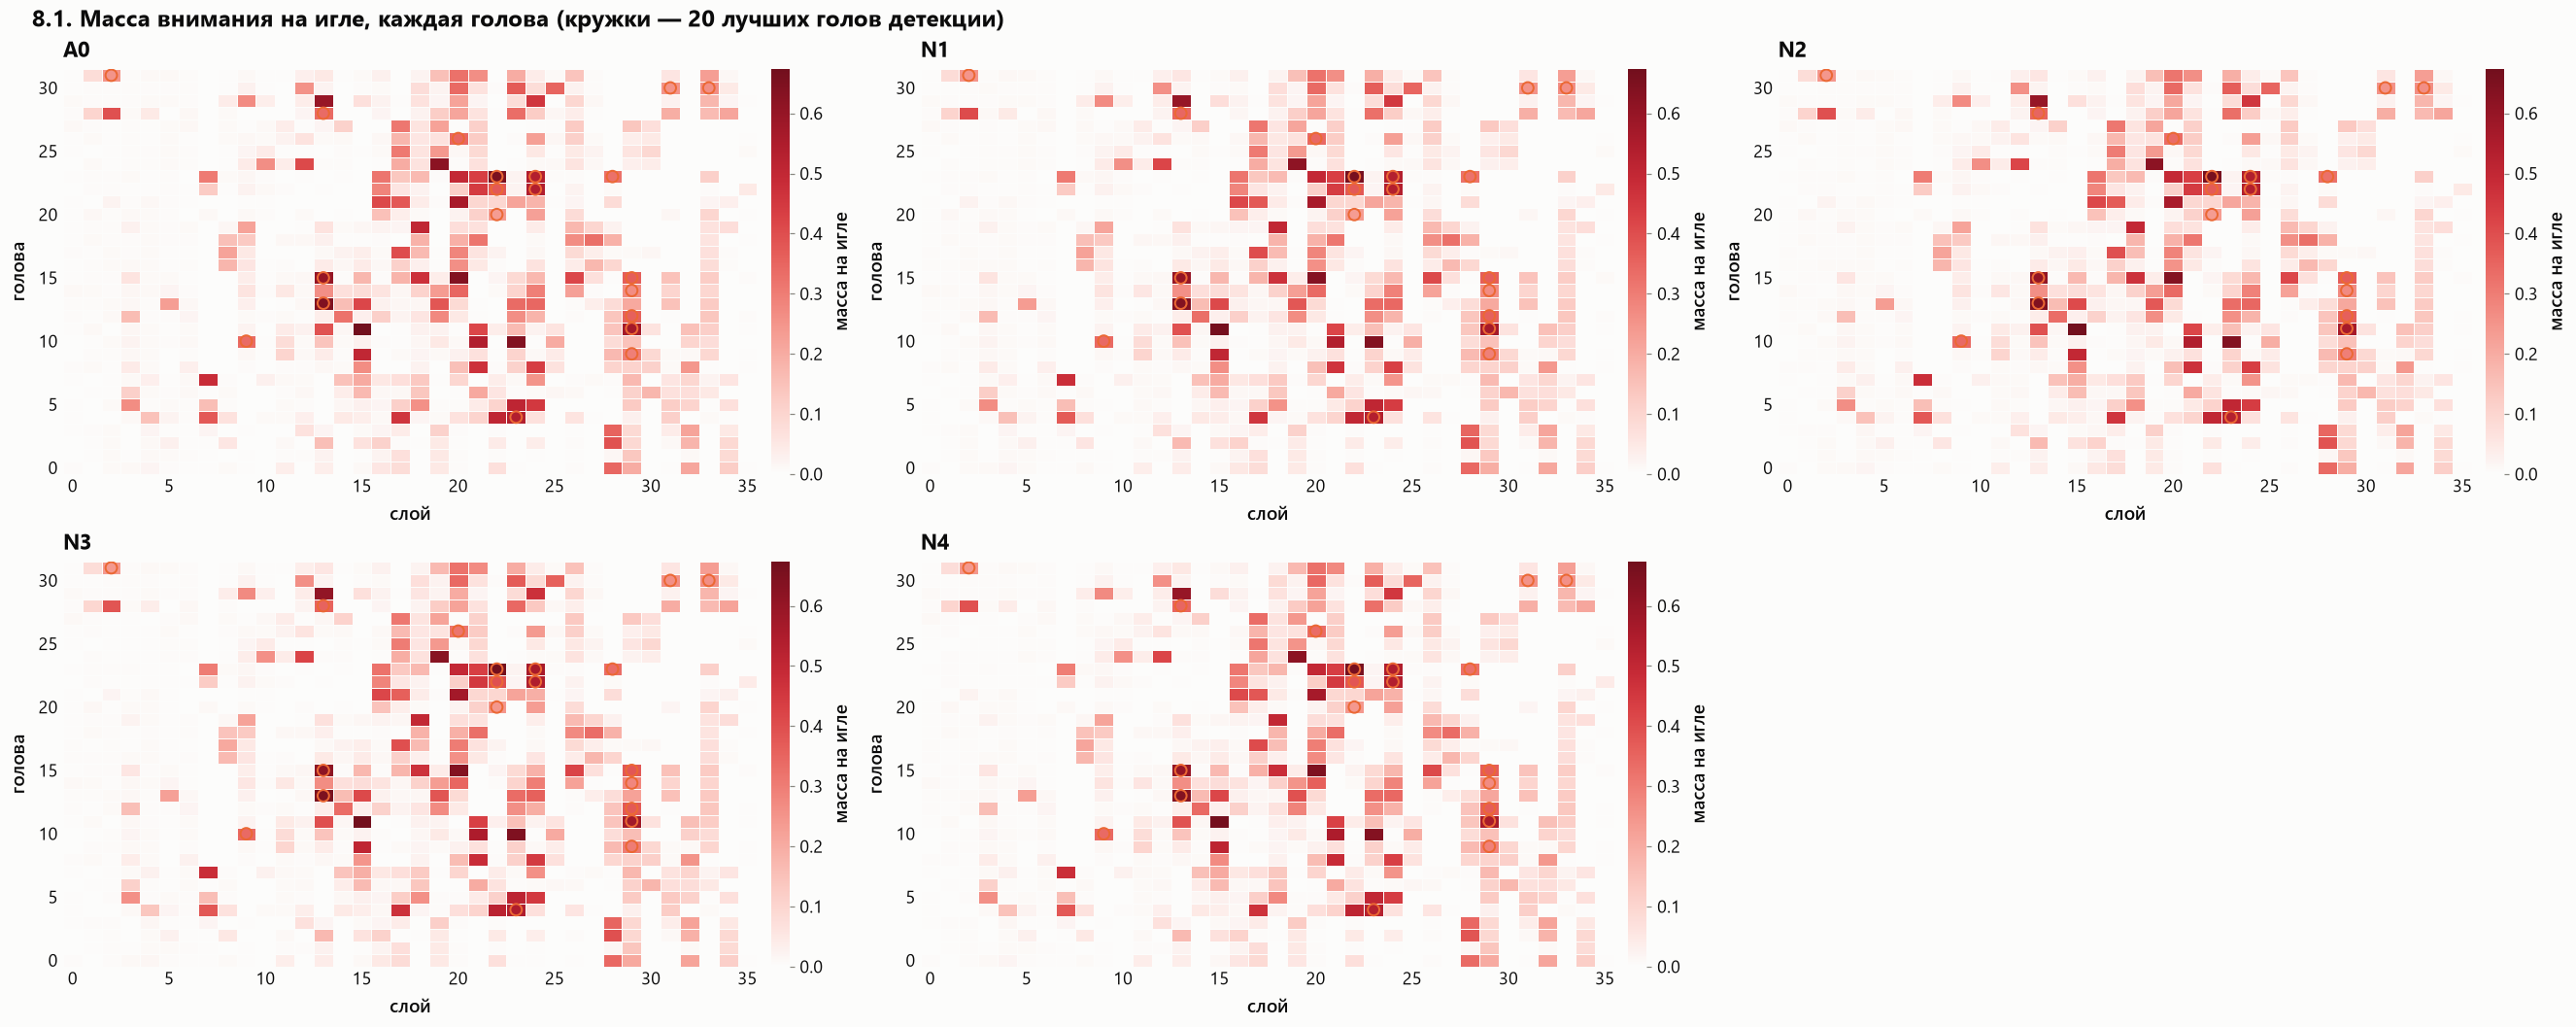

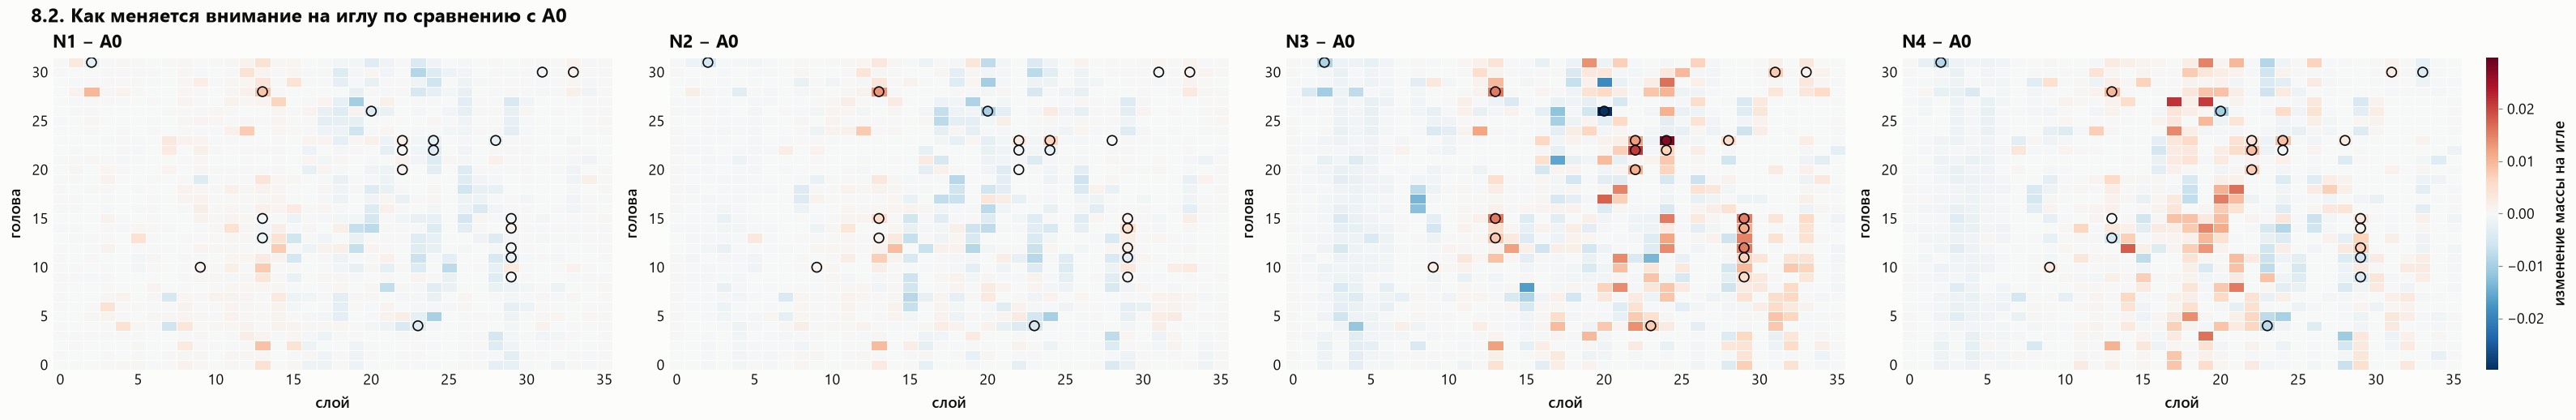

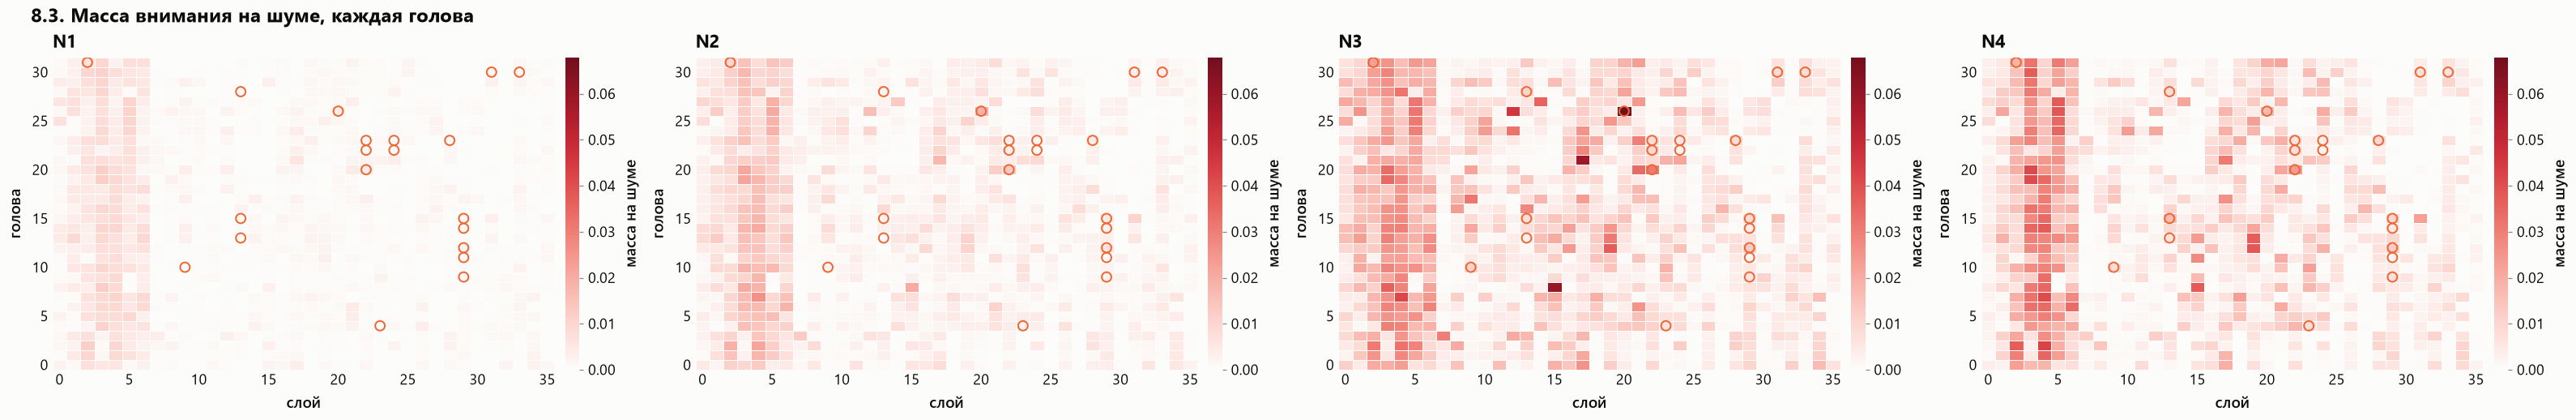

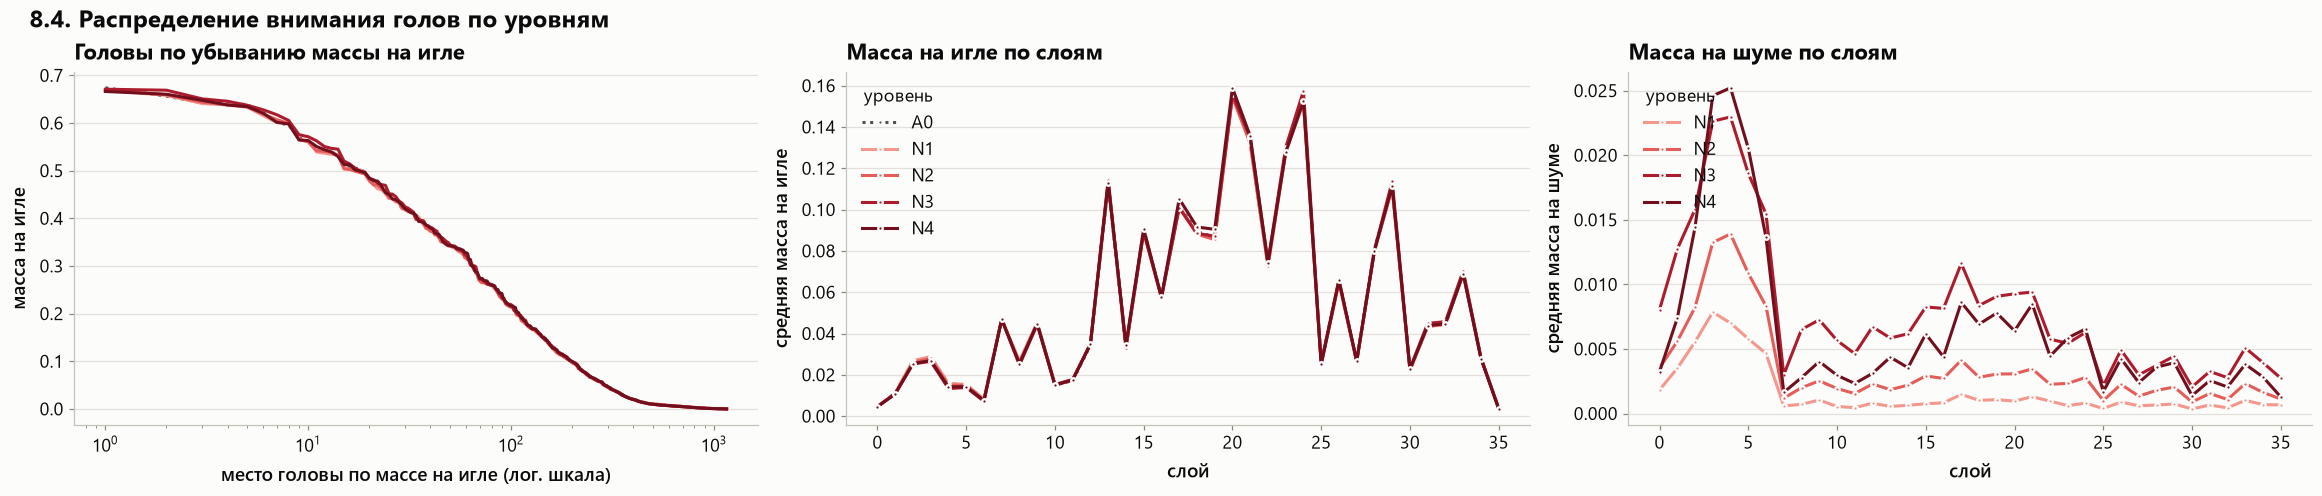

,масса на игле: среднее,медиана,90-й процентиль,голов с массой > 0.1,"доля массы у 20 лучших, %",масса на шуме: среднее,макс. масса на шуме,Спирмен карты с A0,наибольшее падение массы на игле
уровень,,,,,,,,,
A0,0.0565,0.0079,0.1828,197,12.4514,NaN,NaN,1.0000,
N1,0.0563,0.0081,0.1812,197,12.4758,0.0016,0.0124,0.9998,-0.010 (19-27)
N2,0.0561,0.0078,0.1819,196,12.5520,0.0035,0.0260,0.9997,-0.010 (20-29)
N3,0.0566,0.0072,0.1868,198,12.6651,0.0078,0.0679,0.9989,-0.030 (20-26)
N4,0.0567,0.0074,0.1847,198,12.4210,0.0064,0.0429,0.9990,-0.011 (28-3)


In [60]:
# средняя масса каждой головы по примерам уровня: [слой, голова]
needle_maps = {lv: np.nanmean(head_arrays["needle_sentence_mass"][(head_samples["level"] == lv).to_numpy()], axis=0) for lv in LEVELS}
noise_maps = {lv: np.nanmean(head_arrays["competing_mass"][(head_samples["level"] == lv).to_numpy()], axis=0) for lv in LEVELS[1:]}
marks = [(LAYERS[i // N_HEADS], i % N_HEADS) for i in np.flatnonzero(chosen.ravel())]

# 8.1. масса на игле, общая шкала
vmax = max(float(m.max()) for m in needle_maps.values())
fig, axes = plt.subplots(2, 3, figsize=style.size(24, 9.5))
for ax, lv in zip(axes.ravel(), LEVELS):
    plots.head_heatmap(needle_maps[lv], LAYERS, vmax=vmax, mark=marks, ax=ax, label="масса на игле", title=lv)
for ax in axes.ravel()[len(LEVELS):]:
    ax.set_visible(False)
fig.suptitle(f"8.1. Масса внимания на игле, каждая голова (кружки — {TOP} лучших голов детекции)", x=0.01, ha="left", fontweight="bold")
show(axes, "axisN_needle_maps")


# 8.2. разность с A0
def diff_heatmap(diff, ax, title, limit):
    mesh = ax.pcolormesh(plots.edges(LAYERS), np.arange(N_HEADS + 1) - 0.5, diff.T, cmap="RdBu_r", vmin=-limit, vmax=limit,
                         edgecolors=T.surface, linewidth=0.5 * T.scale)
    ax.scatter([l for l, _ in marks], [h for _, h in marks], s=60 * T.scale ** 2, facecolors="none", edgecolors=T.ink, linewidths=1.1)
    plots.round_axis(ax, "x", min(LAYERS), max(LAYERS), 5)
    plots.round_axis(ax, "y", 0, N_HEADS - 1, 5)
    ax.grid(False)
    ax.tick_params(length=0)
    for side in ax.spines.values():
        side.set_visible(False)
    ax.set_xlabel("слой")
    ax.set_ylabel("голова")
    plots.titles(ax, title)
    return mesh

diffs = {lv: needle_maps[lv] - needle_maps["A0"] for lv in LEVELS[1:]}
limit = max(float(np.abs(d).max()) for d in diffs.values())
fig, axes = plt.subplots(1, len(diffs), figsize=style.size(7.2 * len(diffs), 4.6))
for ax, (lv, d) in zip(axes, diffs.items()):
    mesh = diff_heatmap(d, ax, f"{lv} − A0", limit)
bar = fig.colorbar(mesh, ax=axes, pad=0.01, aspect=25)
bar.set_label("изменение массы на игле")
bar.outline.set_visible(False)
fig.suptitle("8.2. Как меняется внимание на иглу по сравнению с A0", x=0.01, ha="left", fontweight="bold")
show(axes, "axisN_needle_diff")

# 8.3. масса на шуме
vmax_noise = max(float(m.max()) for m in noise_maps.values())
fig, axes = plt.subplots(1, len(noise_maps), figsize=style.size(7.2 * len(noise_maps), 4.6))
for ax, (lv, m) in zip(axes, noise_maps.items()):
    plots.head_heatmap(m, LAYERS, vmax=vmax_noise, mark=marks, ax=ax, label="масса на шуме", title=lv)
fig.suptitle("8.3. Масса внимания на шуме, каждая голова", x=0.01, ha="left", fontweight="bold")
show(axes, "axisN_noise_maps")

# 8.4. распределение по головам и по слоям
level_colors = dict(zip(LEVELS, [T.colors["none"]] + style.ordered(len(LEVELS) - 1)))
fig, axes = plt.subplots(1, 3, figsize=style.size(21, 4.4))
for lv in LEVELS:
    line_kw = dict(color=level_colors[lv], label=lv, linestyle=(0, (1, 1.5)) if lv == "A0" else "-")
    axes[0].plot(np.arange(1, needle_maps[lv].size + 1), np.sort(needle_maps[lv].ravel())[::-1], **line_kw)
    axes[1].plot(LAYERS, needle_maps[lv].mean(1), marker="o", markersize=3, **line_kw)
    if lv != "A0":
        axes[2].plot(LAYERS, noise_maps[lv].mean(1), marker="o", markersize=3, **line_kw)
axes[0].set_xscale("log")
axes[0].set_xlabel("место головы по массе на игле (лог. шкала)")
axes[0].set_ylabel("масса на игле")
plots.titles(axes[0], "Головы по убыванию массы на игле")
for ax, ylabel, title in ((axes[1], "средняя масса на игле", "Масса на игле по слоям"), (axes[2], "средняя масса на шуме", "Масса на шуме по слоям")):
    plots.round_axis(ax, "x", min(LAYERS), max(LAYERS), 5)
    ax.set_xlabel("слой")
    ax.set_ylabel(ylabel)
    plots.titles(ax, title)
axes[1].legend(loc="upper left", title="уровень")
axes[2].legend(loc="upper left", title="уровень")
fig.suptitle("8.4. Распределение внимания голов по уровням", x=0.01, ha="left", fontweight="bold")
show(axes, "axisN_distribution")

# сводка по уровням
rows = []
for lv in LEVELS:
    m = needle_maps[lv].ravel()
    worst = int(diffs[lv].argmin()) if lv in diffs else None
    rows.append({"уровень": lv, "масса на игле: среднее": m.mean(), "медиана": np.median(m), "90-й процентиль": np.percentile(m, 90),
                 "голов с массой > 0.1": int((m > 0.1).sum()), f"доля массы у {TOP} лучших, %": 100 * needle_maps[lv][chosen].sum() / m.sum(),
                 "масса на шуме: среднее": noise_maps[lv].mean() if lv in noise_maps else np.nan,
                 "макс. масса на шуме": noise_maps[lv].max() if lv in noise_maps else np.nan,
                 "Спирмен карты с A0": data.spearman(needle_maps[lv], needle_maps["A0"]),
                 "наибольшее падение массы на игле": f"{diffs[lv].ravel()[worst]:.3f} ({LAYERS[worst // N_HEADS]}-{worst % N_HEADS})" if worst is not None else ""})
pd.DataFrame(rows).set_index("уровень").round(4)

## 9. Длина ответа по уровням

Длина ответа в токенах (`n_tokens`, предел генерации — 256) по уровням и прогонам. Отдельно отмечены ответы с **вводной фразой** — «Based on the content of the book, the answer to the question "…" is: **Answer: …**»: модель повторяет вопрос и только потом отвечает, и такой ответ примерно вдвое длиннее обычного.

| Рисунок | Что показывает |
|---|---|
| 9.1 | средняя длина ответа по уровням, линия на прогон, с 95% интервалом |
| 9.2 | доля ответов с вводной фразой и средняя длина ответов **без** неё |
| 9.3 | средняя длина по семействам |

В конце — таблица по уровням и прогонам и самые длинные ответы каждого прогона.

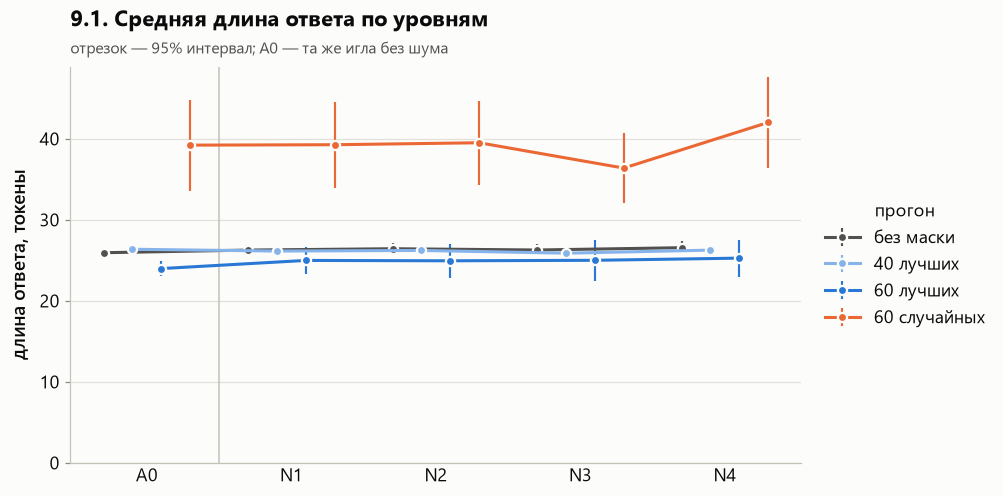

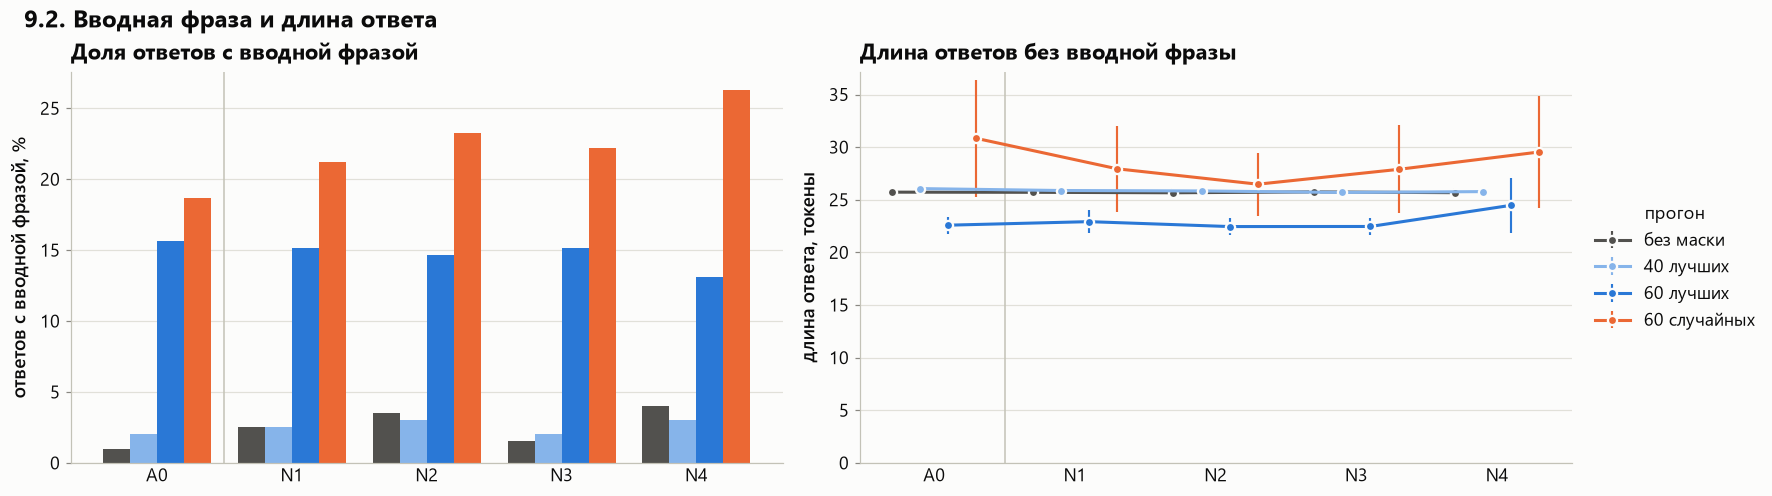

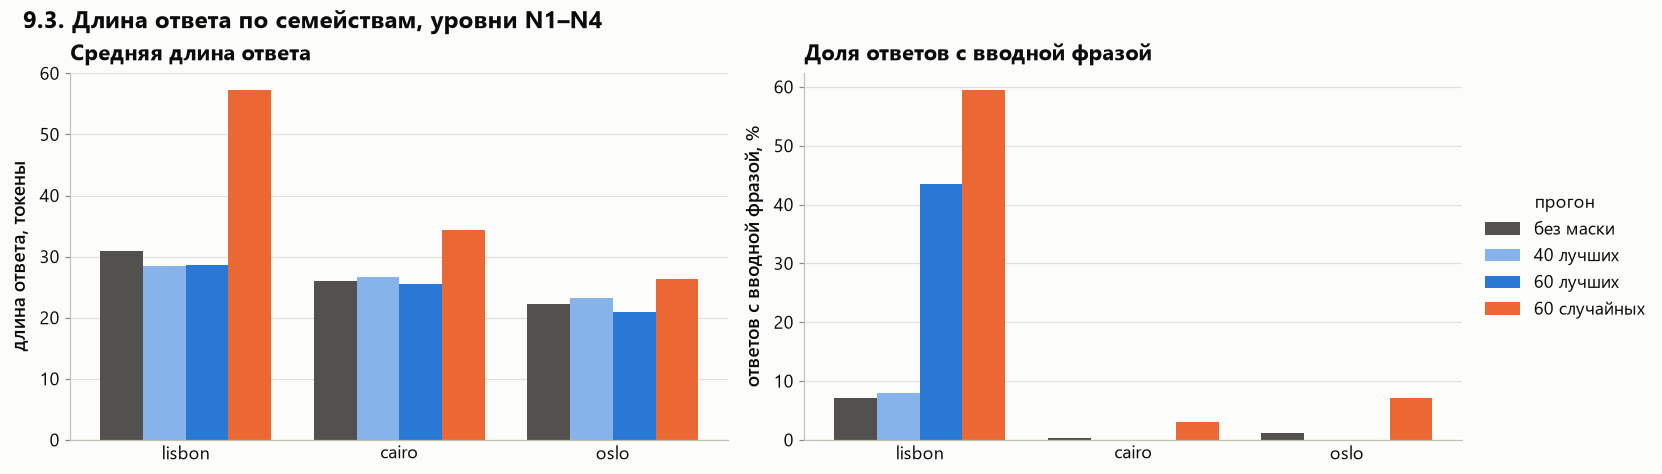

средняя  медиана  процентиль_90  длиннее_40_проц  \
level run                                                          
A0    none         25.9     26.0           29.0              1.0   
      top40        26.4     26.0           30.0              0.5   
      top60        24.0     22.0           27.3              2.0   
      random60     39.2     26.0           62.3             20.7   
N1    none         26.3     26.0           29.0              2.5   
      top40        26.2     26.0           30.0              0.5   
      top60        25.0     22.5           31.0              2.5   
      random60     39.3     26.0           63.0             22.2   
N2    none         26.4     26.0           29.0              3.5   
      top40        26.2     26.0           30.0              0.5   
      top60        25.0     22.0           31.0              3.0   
      random60     39.5     26.0           63.0             23.7   
N3    none         26.3     26.0           29.0              1.5   
      top40        25.9     26.0           29.0              0.0   
      top60        25.0     22.0           27.0              2.0   
      random60     36.4     26.0           62.0             23.2   
N4    none         26.6     26.0           29.0              3.0   
      top40        26.3     26.0           30.0              0.5   
      top60        25.3     22.0           28.9              2.0   
      random60     42.0     26.0           83.9             27.8   

                с_вводной_проц  до_предела_проц  
level run                                        
A0    none                 1.0              0.0  
      top40                2.0              0.0  
      top60               15.7              0.0  
      random60            18.7              2.0  
N1    none                 2.5              0.0  
      top40                2.5              0.0  
      top60               15.2              0.0  
      random60            21.2              1.5  
N2    none                 3.5              0.0  
      top40                3.0              0.0  
      top60               14.6              0.0  
      random60            23.2              1.0  
N3    none                 1.5              0.0  
      top40                2.0              0.0  
      top60               15.2              0.5  
      random60            22.2              1.0  
N4    none                 4.0              0.0  
      top40                3.0              0.0  
      top60               13.1              0.0  
      random60            26.3              2.0

n_tokens answer_class  preamble  \
run      level family                                    
none     N3    lisbon        62      correct      True   
         N4    lisbon        61      correct      True   
top40    N4    lisbon        74      correct      True   
         A0    lisbon        57      correct      True   
top60    N3    lisbon       256        other      True   
         N2    lisbon       206        other      True   
random60 N3    cairo        256      correct     False   
         A0    cairo        256      correct     False   

                                                                                                                                                                                                                                                                                                                                                                                                                              response  
run      level family                                                                                                                                                                                                                                                                                                                                                                                                                   
none     N3    lisbon                                                                                                                                 Based on the content of the book, the answer to the question "What is every visitor to the Lisbon Tram Museum asked to do?" is:\n\n**Answer:** Every visitor to the Lisbon Tram Museum is asked to ring the brass bell at the entrance and sign the guest book with a green pen.  
         N4    lisbon                                                                                                                                         Based on the content of the book, the answer to the question "What is every visitor to the Lisbon Tram Museum asked to do?" is:\n\n**Every visitor to the Lisbon Tram Museum is asked to ring the brass bell at the entrance and sign the guest book with a green pen.**  
top40    N4    lisbon                                                                        Based on the content provided, every visitor to the Lisbon Tram Museum is asked to:\n\n**Ringing a brass bell and signing their name in a green pen.**\n\nThis is explicitly stated in the text:  \n*"Every visitor to the Lisbon Tram Museum is asked to ring the brass bell at the entrance and sign the guest book with a green pen."*  
         A0    lisbon                                                                                                                                                    Based on the content provided, the answer to the question "What is every visitor to the Lisbon Tram Museum asked to do?" is:\n\n**Answer:** Every visitor to the Lisbon Tram Museum is asked to ring the brass bell and sign the guest book with a green pen.  
top60    N3    lisbon  Based on the content provided, the answer to the question "What is the purpose of the Lisbon Tram Museum?" is not explicitly stated. However, the context suggests that the Lisbon Tram Museum is a place where visitors can learn about the history and development of tram systems, including the evolution of tram technology and infrastructure. The mention of "the Lisbon Tram" implies that the museu...  
         N2    lisbon  Based on the content provided, the answer to the question "What is the purpose of the Lisbon Tram Museum?" is not directly stated. However, the context suggests that the Lisbon Tram Museum is a place where visitors can learn about the history and development of tram systems, including the Lisbon Tram. The text mentions that the Lisbon Tram is a significant part of the city's transportation his...  
random60 N3    cairo   The famous soup of 

In [61]:
both["preamble"] = both["response"].map(lambda r: plain(r).startswith(("based on", "according to")))   # вводная фраза
both["long"] = both["n_tokens"] >= 40


def mean_ci(values):
    """Среднее и 95% интервал (±1.96 стандартной ошибки)."""
    v = np.asarray(values, dtype=float)
    half = 1.96 * v.std(ddof=1) / np.sqrt(len(v)) if len(v) > 1 else 0.0
    return v.mean(), v.mean() - half, v.mean() + half


def by_level(df, value, runs=RUNS):
    rows = []
    for (level, run), part in df.groupby(["level", "run"]):
        mean, lo, hi = mean_ci(part[value])
        rows.append({"level": level, "run": run, "mean": mean, "lo": lo, "hi": hi, "n": len(part)})
    return pd.DataFrame(rows)


def level_lines(stats, ax, ylabel, title, subtitle=None):
    width = 0.8 / len(RUNS)
    for i, run in enumerate(RUNS):
        part = stats[stats["run"] == run].set_index("level").reindex(LEVELS)
        xs = np.arange(len(LEVELS)) + (i - (len(RUNS) - 1) / 2) * width
        ax.errorbar(xs, part["mean"], yerr=[part["mean"] - part["lo"], part["hi"] - part["mean"]], fmt="o-", color=RUN_COLORS[run],
                    ecolor=RUN_COLORS[run], elinewidth=1.4, capsize=0, label=RUN_LABELS[run])
    ax.axvline(0.5, color=T.axis, linewidth=1)
    ax.set_xticks(range(len(LEVELS)), LEVELS)
    ax.tick_params(axis="x", length=0)
    ax.set_ylabel(ylabel)
    plots.titles(ax, title, subtitle)
    return ax


# 9.1. средняя длина ответа
ax = plt.subplots(figsize=style.size(9, 4.4))[1]
level_lines(by_level(both, "n_tokens"), ax, "длина ответа, токены", "9.1. Средняя длина ответа по уровням", "отрезок — 95% интервал; A0 — та же игла без шума")
ax.set_ylim(bottom=0)
ax.legend(loc="center left", bbox_to_anchor=(1.01, 0.5), title="прогон")
show(ax, "axisN_length")

# 9.2. вводная фраза: доля и длина ответов без неё
fig, axes = plt.subplots(1, 2, figsize=style.size(16, 4.4))
share = both.pivot_table(index="level", columns="run", values="preamble", aggfunc="mean").reindex(index=LEVELS, columns=RUNS) * 100
width = 0.8 / len(RUNS)
for i, run in enumerate(RUNS):
    axes[0].bar(np.arange(len(LEVELS)) + (i - (len(RUNS) - 1) / 2) * width, share[run], width=width, color=RUN_COLORS[run], label=RUN_LABELS[run])
axes[0].axvline(0.5, color=T.axis, linewidth=1)
axes[0].set_xticks(range(len(LEVELS)), LEVELS)
axes[0].tick_params(axis="x", length=0)
axes[0].set_ylabel("ответов с вводной фразой, %")
plots.titles(axes[0], "Доля ответов с вводной фразой")
level_lines(by_level(both[~both["preamble"]], "n_tokens"), axes[1], "длина ответа, токены", "Длина ответов без вводной фразы")
axes[1].set_ylim(bottom=0)
axes[1].legend(loc="center left", bbox_to_anchor=(1.01, 0.5), title="прогон")
fig.suptitle("9.2. Вводная фраза и длина ответа", x=0.01, ha="left", fontweight="bold")
show(axes, "axisN_preamble")

# 9.3. по семействам (уровни N1–N4 вместе)
only_n = both[both["axis"] == AXIS]
fig, axes = plt.subplots(1, 2, figsize=style.size(15, 4.2))
for ax, (value, ylabel, title) in zip(axes, (("n_tokens", "длина ответа, токены", "Средняя длина ответа"),
                                             ("preamble", "ответов с вводной фразой, %", "Доля ответов с вводной фразой"))):
    table = only_n.pivot_table(index="family", columns="run", values=value, aggfunc="mean").reindex(index=FAMILIES, columns=RUNS)
    if value == "preamble":
        table = table * 100
    for i, run in enumerate(RUNS):
        ax.bar(np.arange(len(FAMILIES)) + (i - (len(RUNS) - 1) / 2) * width, table[run], width=width, color=RUN_COLORS[run], label=RUN_LABELS[run])
    ax.set_xticks(range(len(FAMILIES)), FAMILIES)
    ax.tick_params(axis="x", length=0)
    ax.set_ylabel(ylabel)
    plots.titles(ax, title)
axes[-1].legend(loc="center left", bbox_to_anchor=(1.01, 0.5), title="прогон")
fig.suptitle("9.3. Длина ответа по семействам, уровни N1–N4", x=0.01, ha="left", fontweight="bold")
show(axes, "axisN_length_families")

# таблица по уровням и прогонам
length_table = both.groupby(["level", "run"]).agg(
    средняя=("n_tokens", "mean"), медиана=("n_tokens", "median"), процентиль_90=("n_tokens", lambda s: s.quantile(0.9)),
    длиннее_40_проц=("long", "mean"), с_вводной_проц=("preamble", "mean"), до_предела_проц=("stopped", lambda s: 1 - s.mean()))
length_table[["длиннее_40_проц", "с_вводной_проц", "до_предела_проц"]] *= 100
display(length_table.round(1).loc[[(l, r) for l in LEVELS for r in RUNS]])

# самые длинные ответы каждого прогона
pd.set_option("display.max_colwidth", 400)
both.sort_values("n_tokens", ascending=False).groupby("run").head(2).set_index(["run", "level", "family"])[
    ["n_tokens", "answer_class", "preamble", "response"]].loc[RUNS]

### 9.4. Почему длина ответа ведёт себя так

Числа ниже посчитаны по `samples.jsonl` поиском по тексту ответов; графики 9.1–9.3 должны показывать то же.

**Длину определяет форма ответа, а не уровень.** Модель отвечает одним из двух способов:

| Форма | Пример | Длина |
|---|---|---|
| коротко | «Every visitor to the Lisbon Tram Museum is asked to ring the brass bell at the entrance and sign the guest book with a green pen.» | 22–27 токенов |
| с вводной фразой | «Based on the content of the book, the answer to the question "What is every visitor to the Lisbon Tram Museum asked to do?" is: **Answer: Ring the brass bell …**» | около 50 токенов |

Ответов с вводной фразой на оси N (из 792 на прогон): без маски — 23 (2.9%), 40 лучших — 21 (2.7%), 60 лучших — 115 (14.5%), 60 случайных — 184 (23.2%).

1. **Маска случайных голов меняет форму ответа, а не содержание.** При 60 случайных головах ответ по-прежнему дословно верен (784 из 792), но с вводной фразой — вчетверо чаще, чем без маски. Поэтому у этого прогона самая большая средняя длина: ответов длиннее 40 токенов 192 из 792, без маски — 21. Отключённые случайные головы, по-видимому, участвуют в выборе формата ответа, а не в поиске.
2. **Почти всё это — одно семейство.** 312 из 343 ответов с вводной фразой — `lisbon`, при 60 лучших головах — все 115: вопрос «What is every visitor … asked to do?» модель охотно цитирует целиком. Средняя длина по оси держится на одном семействе (рисунок 9.3).
3. **Уровень влияет слабо.** При 60 случайных головах ответов с вводной фразой: A0 — 37, N1 — 42, N2 — 46, N3 — 44, N4 — 52 из 198 (19%, 21%, 23%, 22%, 26%). Стандартная ошибка доли при 198 примерах — около 3 п. п.; N1–N3 от A0 не отличаются, N4 выше на 7 п. п. — на границе значимости. Если это не шум, то совпадение города в шуме чуть чаще подталкивает модель процитировать вопрос.
4. **Маска лучших голов действует в обе стороны.** Сами факты она укорачивает («the bell» вместо «brass bell», «a bowl» вместо «bowl of black clay»), но у `lisbon` добавляет вводную фразу, а изредка модель уходит в пересказ эссе на 80–110 токенов («…is not directly mentioned in the text. However, the book discusses…»); один ответ при 60 лучших дошёл до предела 256 токенов.

**Вывод.** Длина ответа на этой оси — не мера сложности: она отражает формат, который маска меняет независимо от поиска, и почти целиком определяется одним семейством. Сравнивать уровни по длине имеет смысл только для ответов без вводной фразы (правый график 9.2) и внутри семейства.